<a href="https://colab.research.google.com/github/antoniovfonseca/compare-time-series/blob/main/notebooks/2.1.comparisonTimeSeries.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Compare two time series of maps**

---

This notebook compares two time series of raster maps representing the same continuous or binary variable over the same spatial extent and at the exact same time points. Typical applications include comparing two classification methods, two versions of a data product, or a modeled time series against reference data.

> **How to read X and Y:** **Time Series X** is the reference or baseline series, and **Time Series Y** is the comparison series. Follow Section 2 to point the notebook to your data, then run the remaining cells in order.

### Presence Components at Each Time Point

| Component | Meaning |
|:---|:---|
| **Agreement** | Quantity both time series show as present at the same location and time point. |
| **Omission** | Excess quantity present in Time Series X that Time Series Y does not show, where $X > Y$. |
| **Commission** | Excess quantity present in Time Series Y that Time Series X does not show, where $Y > X$. |
| **Space Difference** | Spatial allocation disagreement, where both time series agree on the total quantity at a given time point but disagree on its spatial location because Omission and Commission coexist at different locations. |
| **Time Difference** | Temporal allocation disagreement, equal to the smaller of total Omission and total Commission summed across all time points. Omission at some time points offsets Commission at others, so the two series agree on the cumulative total over time but disagree on *when* it occurred. |

### Change Concepts Across Time Intervals

Change analysis applies the same five components to gains and losses between consecutive time points:

| Concept | Meaning |
|:---|:---|
| **Gross Change** | Tracks gains and losses separately so that a location experiencing both gain and loss across different intervals does not cancel out. |
| **Quantity (Net) Change** | Cancels gains and losses occurring at the same location and interval first, isolating net change. |
| **Sum** | Total change added across all consecutive time intervals. |
| **Extent** | Change measured using only the first and last time points. |
| **Alternation** | Difference between Sum and Extent, capturing back-and-forth transitions that reverse themselves within the full time span. |

> **Spatial comparison maps:** Section 6 maps these components pixel by pixel, showing where Time Series X and Time Series Y agree, where one consistently exceeds the other, and where temporal allocation differences occur for both presence and change.

### Generated Outputs
Results are written to the `OUTPUT_PATH` folder configured in Section 2:

| Folder | Contents | Produced in |
|:---|:---|:---|
| `tables/` | 3 CSV files containing the exact values behind every chart: presence, gross change, and net change | Section 3 |
| `charts/` | 2 PNG stacked-bar figures summarizing agreement and difference components for presence and change | Sections 4–5 |
| `rasters/` | 6 GeoTIFF maps, one value per pixel, for analysis in GIS software | Section 6 |
| `maps/` | 6 PNG map previews ready for reports or visual inspection | Section 6 |


## **1. Environment Setup**

In [36]:
# @title 1.1 Install Dependencies
# @markdown Run this cell only if you are using Google Colab
get_ipython().system('pip -q install matplotlib-scalebar matplotlib-map-utils')

In [37]:
# @title 1.2 Import Modules

# Standard Library Imports
import gc
import os
import re
from contextlib import ExitStack
from typing import Dict, List, Tuple, Union

# Third-party Data & Geospatial Imports
import numpy as np
import pandas as pd
import rasterio
from pyproj import CRS, Geod, Transformer
from rasterio.windows import Window
from tqdm.auto import tqdm

# Matplotlib & Visualization Imports
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.ticker as ticker
from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap, ListedColormap, Normalize
from matplotlib.patches import FancyArrowPatch, Patch, Rectangle
from matplotlib.ticker import FuncFormatter
from matplotlib_map_utils import north_arrow
from matplotlib_scalebar.scalebar import ScaleBar

In [38]:
# @title 1.3 Configure Google Drive
# @markdown Run this cell onlye if your data is stored on Google Drive

try:
    from google.colab import drive
except ModuleNotFoundError:
    print("Google Drive mount skipped: this notebook is running outside Google Colab.")
else:
    drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## **2. Input your data**

Before filling in Section 2.1, check that your raster files meet the data requirements below. When you run cell 2.1, the notebook verifies that your folders and files exist before any calculation starts.

### 1. How your files should be organized
* **Two separate folders:** Put the rasters for Time Series X in one folder and the rasters for Time Series Y in another.
* **One `.tif` file per time point:** Both folders must have one single-band GeoTIFF file for each time point you want to compare, covering the exact same dates.
* **Consistent file names:** Every file in a folder must follow the pattern `{PREFIX}{YEAR}{SUFFIX}`. For example, if your prefix is `forest_imazon_`, the year is `2000`, and the suffix is `.tif`, the notebook looks for `forest_imazon_2000.tif`.

### 2. How your rasters should be formatted
* **Matching pixel grid:** Every file in both time series must have the exact same number of rows and columns, cover the same geographic area, and use the same pixel size and coordinate system (CRS). The notebook stops with an error if image dimensions differ, but it cannot detect if two maps with the same dimensions are shifted in space.
* **Whole-number values representing how much is present:** Each pixel value must be a non-negative whole number (`0, 1, 2, ...`) showing the amount present in that pixel (for example, `1` for present and `0` for absent, a count, or biomass).
  * *If you have a multi-class land-cover map:* Convert it first into a separate map for the single class you want to study (`1` where the class is present, `0` everywhere else).
  * *If your data has decimals (such as probabilities from `0.0` to `1.0`):* The notebook drops decimals when reading pixel values. Multiply your raster by a scale factor (such as `100` or `1000`) and round to whole numbers before using this notebook.
* **One consistent No-Data value:** Every file across both time series must use the same whole number (such as `255`) to mark pixels with missing or masked data. If a pixel has no data at *any* time point in either series, the notebook excludes that pixel from all tables and maps so every result compares the exact same area.

### 3. Parameter guide for Section 2.1

| Group | Parameter | What to enter |
|:---|:---|:---|
| **Path Settings** | `X_FOLDER_PATH` | Full path to the folder with Time Series X rasters. |
| | `Y_FOLDER_PATH` | Full path to the folder with Time Series Y rasters. |
| | `OUTPUT_PATH` | Full path to the folder where tables, charts, and maps will be saved (created automatically if it does not exist). |
| **Time Range** | `YEARS` | Time points separated by commas, in chronological order (for example, `2000,2010,2020`). These must match the numbers in your file names. |
| | `TIME_LABEL_MODE` | Choose `"years"` to show the actual years on chart axes, or `"index"` to number time points as `0, 1, 2, ...`. |
| **Raster Settings** | `NO_DATA_VALUE` | Whole number used in your rasters to mark missing or masked pixels (default is `255`). |
| **Result Units** | `RESULT_UNIT` | Unit used in output tables and charts. Choose `"pixels"` to sum raw pixel values directly, or `"m2"`, `"ha"`, or `"km2"` to multiply each pixel value by the pixel's area on the ground (requires a valid coordinate system in your `.tif` files). |
| **File Names** | `X_FILE_PREFIX` | Text before the year in Time Series X file names (for example, `forest_`). |
| | `Y_FILE_PREFIX` | Text before the year in Time Series Y file names (for example, `forest_`). |
| | `FILE_SUFFIX` | Text after the year, including the file extension (usually `.tif`). |


In [39]:
# @title 2.1 Configure Your App { display-mode: "form" }
# @markdown ### 📂 Path Settings
# @markdown Folder containing the Time Series X raster files:
X_FOLDER_PATH = "/content/drive/MyDrive/Assessments/compare-time-series/imazon_mapbiomas/input/imazon" #@param {type:"string"}
# @markdown Folder containing the Time Series Y raster files:
Y_FOLDER_PATH = "/content/drive/MyDrive/Assessments/compare-time-series/imazon_mapbiomas/input/mapbiomas" #@param {type:"string"}
# @markdown Folder where output tables, charts, and maps will be saved:
OUTPUT_PATH = "/content/drive/MyDrive/Assessments/compare-time-series/imazon_mapbiomas/output" #@param {type:"string"}

# @markdown ### 🗓️ Time Range
# @markdown Years in chronological order, separated by commas (must match the file names):
YEARS = "2000,2010,2020" #@param {type:"string"}
# @markdown Show actual years on chart axes ("years") or sequential numbers 0, 1, 2... ("index"):
TIME_LABEL_MODE = "years" #@param ["years", "index"]
CUSTOM_TIME_LABELS = None

# @markdown ### 🧭 Raster Settings
# @markdown Whole number used in your rasters to mark missing or masked pixels:
NO_DATA_VALUE = 255 #@param {type:"integer"}

# @markdown ### 📏 Result Units
# @markdown Choose "pixels" to sum pixel values directly, or an area unit ("m2", "ha", "km2") to multiply each pixel value by its area:
RESULT_UNIT = "pixels" #@param ["pixels", "m2", "ha", "km2"]

# @markdown ### 🏷️ File Names
# @markdown File names follow `{PREFIX}{YEAR}{SUFFIX}` (e.g., `forest_imazon_` + `2000` + `.tif` -> `forest_imazon_2000.tif`):
X_FILE_PREFIX = "forest_imazon_" #@param {type:"string"}
Y_FILE_PREFIX = "forest_mapbiomas_" #@param {type:"string"}
FILE_SUFFIX = ".tif" #@param {type:"string"}

# Build the paths consumed by the assessment cells.
if isinstance(YEARS, str):
    years = [
        int(year.strip())
        for year in YEARS.split(",")
        if year.strip()
    ]
else:
    years = [int(year) for year in YEARS]
if not years:
    raise ValueError("Please provide at least one year in YEARS.")
if years != sorted(set(years)):
    raise ValueError("YEARS must be unique and in chronological order.")
if RESULT_UNIT not in {"pixels", "m2", "ha", "km2"}:
    raise ValueError("RESULT_UNIT must be 'pixels', 'm2', 'ha', or 'km2'.")
if TIME_LABEL_MODE not in {"years", "index"}:
    raise ValueError("TIME_LABEL_MODE must be 'years' or 'index'.")
if CUSTOM_TIME_LABELS is not None:
    time_labels = [str(label) for label in CUSTOM_TIME_LABELS]
elif TIME_LABEL_MODE == "years":
    time_labels = [str(year) for year in years]
else:
    time_labels = [str(index) for index in range(len(years))]
if len(time_labels) != len(years):
    raise ValueError("CUSTOM_TIME_LABELS must have the same length as YEARS.")
interval_labels = [
    f"{time_labels[index]}-{time_labels[index + 1]}"
    for index in range(len(time_labels) - 1)
]

time_series_x = [
    os.path.join(X_FOLDER_PATH, f"{X_FILE_PREFIX}{year}{FILE_SUFFIX}")
    for year in years
]
time_series_y = [
    os.path.join(Y_FOLDER_PATH, f"{Y_FILE_PREFIX}{year}{FILE_SUFFIX}")
    for year in years
]

no_data_value = NO_DATA_VALUE
output_path = OUTPUT_PATH

# Create the output folder if it does not exist, then validate input folders and files.
os.makedirs(OUTPUT_PATH, exist_ok=True)
missing_paths = [
    path for path in [X_FOLDER_PATH, Y_FOLDER_PATH]
    if not os.path.exists(path)
]
missing_files = [
    path for path in time_series_x + time_series_y
    if not os.path.isfile(path)
]

if missing_paths or missing_files:
    print("Configuration needs attention.")
    if missing_paths:
        print("Missing folders:")
        for path in missing_paths:
            print(f"  - {path}")
    if missing_files:
        print("Missing raster files:")
        for path in missing_files:
            print(f"  - {path}")
else:
    print(f"Ready to process {len(years)} years of maps.")


Ready to process 3 years of maps.


In [40]:
# @title 2.2 Prepare Multi-Timepoint Raster Processing
# @markdown This cell prepares the shared raster-processing helpers used by the
# @markdown assessment and map-generation steps. No user changes are required.
import threading
from concurrent.futures import (
    FIRST_COMPLETED,
    ThreadPoolExecutor,
    as_completed,
    wait,
)

_thread_local_eq = threading.local()


def _get_thread_datasets_eq(
    x_paths: Tuple[str, ...],
    y_paths: Tuple[str, ...],
):
    """
    Returns (srcs_x, srcs_y) — tuples of open rasterio datasets, one per
    time point, cached per worker thread. Rasterio datasets aren't safe
    to share across threads, but each thread keeping its own open
    handles (reused across blocks/calls) is the documented safe
    pattern. Shared by both the CSV table computations (presence +
    change assessment) and the equation-map raster generation — both
    read the same T+1 X/Y time series, just aggregating differently.
    """
    key = (x_paths, y_paths)
    cache = getattr(_thread_local_eq, "datasets", None)

    if cache is None or cache["key"] != key:
        if cache is not None:
            for src in cache["srcs_x"] + cache["srcs_y"]:
                src.close()
        cache = {
            "key": key,
            "srcs_x": tuple(
                rasterio.open(p) for p in x_paths
            ),
            "srcs_y": tuple(
                rasterio.open(p) for p in y_paths
            ),
        }
        _thread_local_eq.datasets = cache

    return cache["srcs_x"], cache["srcs_y"]


def _generate_uniform_windows(
    width: int,
    height: int,
    block_width: int = 1024,
    block_height: int = 1024,
):
    """
    Fallback window generator for when the input rasters don't share
    a compatible block layout — reads all of them on the SAME grid
    instead of one file's native tiling.
    """
    for row_off in range(0, height, block_height):
        h = min(block_height, height - row_off)
        for col_off in range(0, width, block_width):
            w = min(block_width, width - col_off)
            yield Window(col_off, row_off, w, h)


def _resolve_windows_eq(srcs: List) -> List[Window]:
    """
    Picks the window strategy for reading all T+1 X and Y rasters
    together: native block layout (fast path) when every raster shares
    the same dimensions and block size; a uniform grid otherwise.
    """
    dims = {
        (s.width, s.height) for s in srcs
    }
    if len(dims) > 1:
        raise ValueError(
            f"All X and Y rasters must have matching dimensions; got {dims}."
        )

    same_blocks = len(
        {tuple(s.block_shapes) for s in srcs}
    ) == 1

    if same_blocks:
        return [
            window for _, window in srcs[0].block_windows()
        ]

    print(
        "  [warning] input rasters have different internal block "
        "layouts; reading with a uniform window grid instead of "
        "native tiling."
    )
    width, height = next(iter(dims))
    return list(
        _generate_uniform_windows(width, height)
    )


UNIT_FACTORS_M2 = {
    "m2": 1.0,
    "ha": 1.0e4,
    "km2": 1.0e6,
}
UNIT_LABELS = {
    "pixels": "pixels",
    "m2": "m²",
    "ha": "ha",
    "km2": "km²",
}


def compute_row_areas_m2(
    raster_path: str,
) -> np.ndarray:
    """
    Calculate the area of one pixel in each row of a raster, in square
    meters.

    In a projected CRS, every pixel has the same area, equal to the pixel
    width times the pixel height converted to meters. In a geographic CRS,
    pixel area depends on latitude, so the area of one pixel in each row
    is calculated on the ellipsoid of the CRS.

    Parameters
    ----------
    raster_path : str
        Path to a raster that defines the grid shared by all inputs.

    Returns
    -------
    numpy.ndarray
        Area of one pixel in each row, in square meters, with one value
        per row.

    Raises
    ------
    ValueError
        If the raster has no CRS or a rotated grid.
    """
    with rasterio.open(raster_path) as src:
        transform = src.transform
        crs = src.crs
        height = src.height

    if crs is None:
        raise ValueError(
            f"{raster_path} has no CRS, so pixel area cannot be calculated."
        )
    if transform.b != 0 or transform.d != 0:
        raise ValueError(
            f"{raster_path} has a rotated grid, which is not supported."
        )

    if crs.is_geographic:
        geod = CRS.from_wkt(crs.to_wkt()).get_geod()
        lon_left = transform.c
        lon_right = transform.c + transform.a
        areas = np.empty(
            height,
            dtype=np.float64,
        )
        for row in range(height):
            lat_top = transform.f + row * transform.e
            lat_bottom = lat_top + transform.e
            area, _ = geod.polygon_area_perimeter(
                [lon_left, lon_right, lon_right, lon_left],
                [lat_top, lat_top, lat_bottom, lat_bottom],
            )
            areas[row] = abs(area)
        return areas

    meters_per_unit = crs.linear_units_factor[1]
    pixel_area = abs(transform.a * transform.e) * meters_per_unit ** 2
    return np.full(
        height,
        pixel_area,
        dtype=np.float64,
    )


def compute_row_weights(
    raster_path: str,
    result_unit: str,
) -> np.ndarray:
    """
    Calculate the weight of one pixel in each row for the chosen unit.

    Parameters
    ----------
    raster_path : str
        Path to a raster that defines the grid shared by all inputs.
    result_unit : str
        One of "pixels", "m2", "ha", or "km2".

    Returns
    -------
    numpy.ndarray
        Weight of one pixel in each row. The weight is 1 for "pixels" and
        the pixel area in the chosen unit otherwise.
    """
    if result_unit == "pixels":
        with rasterio.open(raster_path) as src:
            height = src.height
        return np.ones(
            height,
            dtype=np.float64,
        )
    return compute_row_areas_m2(raster_path) / UNIT_FACTORS_M2[result_unit]


## **3. Presence and Change Components**

This section reads your rasters once and calculates every number used
later. The presence results feed Section 4, and the change results feed
Section 5. Run cell 3.2 once - it can take a while on large rasters. Its
output is the three tables listed under `tables/` above; open them
directly, for example in Excel or pandas, if you want the raw numbers in
addition to, or instead of, the charts.


In [41]:
# @title 3.1 Prepare Chart Visualization Tools
# @markdown This cell prepares the common display tools used by the charts below:
# @markdown 1. Choose readable scales and axis intervals.
# @markdown 2. Apply consistent colors and hatch patterns.
# @markdown 3. Create legends for presence, gain, and loss components.
# @markdown 4. Keep the chart style consistent across the analysis results.

def _fixed_step_yticks(
    top_value,
    target_ticks=8,
    min_ticks=3,
    max_ticks=20,
):
    """
    Builds Y-axis ticks with EQUAL intervals.

    For integer-valued maxima (e.g. small validated pixel counts like
    the toy data), searches for an EXACT divisor of the max so the
    axis ends precisely on the true value — useful when the exact
    number needs to be checkable.

    For non-integer maxima (the common case for real datasets after
    scaling to "million/billion pixels"), an exact divisor essentially
    never exists, so instead this picks the "nicest" round step
    (1/2/2.5/5/10 x 10^k) whose resulting tick count is closest to
    target_ticks, and the axis ends on the next nice multiple at or
    above the true max — the standard way charts show round gridlines.

    Parameters
    ----------
    top_value : float
        The true maximum value the axis must cover.
    target_ticks : int, optional
        Preferred number of intervals. Default is 8.
    min_ticks : int, optional
        Minimum acceptable number of intervals. Default is 3.
    max_ticks : int, optional
        Maximum acceptable number of intervals. Default is 20.

    Returns
    -------
    np.ndarray
        Tick positions from 0 up to (at least) top_value, evenly spaced.
    """
    if top_value <= 0:
        return np.array([0])

    is_intlike = abs(top_value - round(top_value)) < 1e-6

    if is_intlike:
        tv_int = round(top_value)
        divs = set()
        i = 1
        while i * i <= tv_int:
            if tv_int % i == 0:
                divs.add(i)
                divs.add(tv_int // i)
            i += 1
        candidates_n = list(divs)

        valid = [
            n for n in candidates_n
            if min_ticks <= n <= max_ticks
        ]
        if valid:
            n_intervals = min(
                valid,
                key=lambda n: abs(n - target_ticks),
            )
        elif candidates_n:
            n_intervals = min(
                candidates_n,
                key=lambda n: abs(n - max_ticks),
            )
        else:
            n_intervals = 1

        step = top_value / n_intervals
        return np.arange(
            0,
            top_value + step / 2,
            step,
        )

    # Non-integer top: pick the nicest round step whose tick count is
    # closest to target_ticks, without requiring exact divisibility.
    magnitude = 10 ** np.floor(np.log10(top_value))
    candidate_steps = sorted({
        base * magnitude * mult
        for base in (1, 2, 2.5, 5, 10)
        for mult in (0.1, 1, 10)
    })

    best_step, best_score = None, None
    for step in candidate_steps:
        n = top_value / step
        if min_ticks <= n <= max_ticks:
            score = abs(n - target_ticks)
            if best_score is None or score < best_score:
                best_step, best_score = step, n

    if best_step is None:
        best_step = top_value / target_ticks

    n_ticks_needed = int(
        np.ceil(top_value / best_step)
    )
    return np.arange(
        0,
        (n_ticks_needed + 1) * best_step,
        best_step,
    )


def _scale_dynamic(max_val):
    """
    Picks a scale factor and unit label for a value, using the same
    benchmark thresholds across every bar chart (presence, gross
    change, net change), so "hundred/thousand/million/... pixels" is
    decided consistently everywhere.

    Parameters
    ----------
    max_val : float
        The largest value the chart needs to display.

    Returns
    -------
    Tuple[float, str]
        (scale_factor, unit_name) — e.g. (1000, "thousand pixels").
        unit_name is "pixels" (no scaling) below the first threshold.
    """
    scale_benchmarks = [
        (1e12, 1e12, "trillion"),
        (1e9, 1e9, "billion"),
        (1e6, 1e6, "million"),
        (1e3, 1e3, "thousand"),
    ]
    unit = UNIT_LABELS[RESULT_UNIT]
    for threshold, factor, label in scale_benchmarks:
        if max_val >= threshold:
            return factor, f"{label} {unit}"
    return 1, unit


def _apply_hatches(
    ax,
    hatches,
    edgecolor='#3a3a3a',
    linewidth=0.3,
):
    """
    Applies hatch patterns to the bar containers currently on `ax`, in
    the same order the columns were plotted. For diverging charts with
    two .plot() calls (Gain then Loss), pass `hatches * 2` so both
    halves get the matching per-category pattern. `None` entries in
    `hatches` leave that category's patches solid (untouched), since
    hatch lines need an edgecolor to render — which is why hatched
    categories get one here while solid ones don't.

    Parameters
    ----------
    ax : matplotlib.axes.Axes
        The axes whose bar containers should be hatched.
    hatches : list
        One entry per container, in plotting order. `None` = solid.
    edgecolor : str, optional
        Edge color used to draw the hatch lines. Default '#3a3a3a'.
    linewidth : float, optional
        Edge line width for hatched patches. Default 0.3.

    Returns
    -------
    None
        The axis is updated in place.
    """
    for container, hatch in zip(ax.containers, hatches):
        if hatch:
            for patch in container.patches:
                patch.set_hatch(hatch)
                patch.set_edgecolor(edgecolor)
                patch.set_linewidth(linewidth)


def _build_diverging_legend(
    ax,
    df_gain,
    df_loss,
    metrics_order,
    colors_gain,
    colors_loss,
    hatches,
    full_order,
    loss_label_override=None,
):
    """
    Builds the Gain/Loss legend shared by the four diverging bar charts
    (gross change intervals/sum-extent, net change intervals/sum-extent):
    only categories with a non-zero value across the plotted bars are
    shown, in Fig. 2f/2h's exact top-to-bottom order.

    `loss_label_override` optionally renames Loss-side labels (e.g.
    "y>x" -> "|y|>|x|" for net change, since loss is stored as a
    negative quantity and comparing which side lost more only makes
    sense in terms of magnitude); Gain labels are always left as-is.

    Parameters
    ----------
    ax : matplotlib.axes.Axes
        The axes to attach the legend to.
    df_gain, df_loss : pd.DataFrame
        The (already scaled) Gain and Loss data, indexed by bar label,
        used only to check which categories are non-zero.
    metrics_order : list
        Column names in stacking order (bottom to top).
    colors_gain, colors_loss : list
        Colors aligned with metrics_order, for Gain and Loss respectively.
    hatches : list
        Hatch patterns aligned with metrics_order (None = solid).
    full_order : list of (str, str)
        (Change_Type, label) pairs in the desired top-to-bottom legend
        order, e.g. [('Gain','x>y'), ('Gain','y>x'), ..., ('Loss','Agreement')].
    loss_label_override : dict, optional
        Maps a label to its Loss-side display text, e.g.
        {'y>x': '|y|>|x|', 'x>y': '|x|>|y|'}. Default None (no override).

    Returns
    -------
    matplotlib.legend.Legend
    """
    loss_label_override = loss_label_override or {}

    color_hatch_by_key = {
        ('Gain', lbl): (colors_gain[i], hatches[i])
        for i, lbl in enumerate(metrics_order)
    }
    color_hatch_by_key.update({
        ('Loss', lbl): (colors_loss[i], hatches[i])
        for i, lbl in enumerate(metrics_order)
    })

    legend_elements = [
        mpatches.Patch(
            facecolor=color_hatch_by_key[key][0],
            hatch=color_hatch_by_key[key][1],
            edgecolor='#3a3a3a' if color_hatch_by_key[key][1] else 'none',
            linewidth=0.3 if color_hatch_by_key[key][1] else 0,
            label=(
                f"{key[0]} "
                f"{loss_label_override.get(key[1], key[1]) if key[0] == 'Loss' else key[1]}"
            ),
        )
        for key in full_order
        if (
            df_gain[key[1]].sum() if key[0] == 'Gain'
            else df_loss[key[1]].abs().sum()
        ) > 0
    ]

    return ax.legend(
        handles=legend_elements,
        bbox_to_anchor=(1.02, 0.5),
        loc='center left',
        frameon=False,
        fontsize=12,
    )

In [43]:
# @title 3.2 Calculate Presence and Change Results
# @markdown This cell compares the two time series and creates three result tables:
# @markdown 1. Presence agreement and differences for each time point.
# @markdown 2. Gross change components for each time interval.
# @markdown 3. Net change components for each time interval.
# @markdown
# @markdown The tables are saved in the `tables` folder and used by the charts
# @markdown in Section 4. The cell then checks that the components in each
# @markdown table add up to their totals.

def _read_and_compute_full_block(
    x_paths: Tuple[str, ...],
    y_paths: Tuple[str, ...],
    window: Window,
    no_data_val: int,
    row_weights: np.ndarray,
) -> Tuple[
    List[Dict[str, float]],
    List[Dict[str, float]],
    Dict[str, float],
]:
    """
    Read one portion of every map and calculate the comparison metrics
    needed for presence and change assessment.

    A pixel enters the metrics only where every time point of both time
    series is valid, so presence, change, and the maps all use the same
    pixels. Each pixel value is multiplied by the weight of its row
    before summing, which converts the sums to the unit of the results.

    Parameters
    ----------
    x_paths : tuple of str
        Paths to the Time Series X rasters in chronological order.
    y_paths : tuple of str
        Paths to the Time Series Y rasters in chronological order.
    window : rasterio.windows.Window
        Portion of the rasters to read.
    no_data_val : int
        Pixel value treated as invalid data.
    row_weights : numpy.ndarray
        Weight of one pixel in each row of the full raster.

    Returns
    -------
    (presence_per_year, interval_metrics, extent_metrics)
        Tuple containing presence metrics per time point, change metrics per
        interval, and change metrics for the full time extent.
    """
    srcs_x, srcs_y = _get_thread_datasets_eq(
        x_paths,
        y_paths,
    )
    arr_x_t = [
        s.read(1, window=window).astype(np.int64) for s in srcs_x
    ]
    arr_y_t = [
        s.read(1, window=window).astype(np.int64) for s in srcs_y
    ]
    num_times = len(arr_x_t)

    # 1. Build the common mask and set invalid pixels to zero.
    valid = np.ones_like(
        arr_x_t[0],
        dtype=bool,
    )
    for ax, ay in zip(arr_x_t, arr_y_t):
        valid &= (ax != no_data_val) & (ay != no_data_val)
    arr_x_t = [np.where(valid, ax, 0) for ax in arr_x_t]
    arr_y_t = [np.where(valid, ay, 0) for ay in arr_y_t]

    row_start = int(window.row_off)
    weights = row_weights[row_start:row_start + int(window.height)]

    def _weighted_sum(values):
        """Sum the pixel values of the block, weighted by row."""
        row_sums = values.sum(
            axis=1,
            dtype=np.float64,
        )
        return float(row_sums @ weights)

    # 2. Calculate presence agreement and differences for each time point.
    presence_per_year = []
    for t in range(num_times):
        x_valid, y_valid = arr_x_t[t], arr_y_t[t]
        presence_per_year.append({
            "agreement_sum": _weighted_sum(np.minimum(x_valid, y_valid)),
            "x_sum": _weighted_sum(x_valid),
            "y_sum": _weighted_sum(y_valid),
        })

    def _change_metrics(x0, x1, y0, y1):
        """
        Calculate agreement, gains, and losses between two time points.

        Parameters
        ----------
        x0, x1, y0, y1 : numpy.ndarray
            Corresponding maps at the beginning and end of an interval,
            with invalid pixels already set to zero.

        Returns
        -------
        dict of str to float
            Aggregated agreement, gain, and loss values.
        """
        dx = x1 - x0
        dy = y1 - y0
        gain_x, gain_y = np.maximum(0, dx), np.maximum(0, dy)
        loss_x, loss_y = np.maximum(0, -dx), np.maximum(0, -dy)
        return {
            "gh": _weighted_sum(np.minimum(gain_x, gain_y)),
            "gx": _weighted_sum(gain_x),
            "gy": _weighted_sum(gain_y),
            "lh": _weighted_sum(np.minimum(loss_x, loss_y)),
            "lx": _weighted_sum(loss_x),
            "ly": _weighted_sum(loss_y),
        }

    # 3. Calculate gross and net change inputs for each interval.
    interval_metrics = [
        _change_metrics(
            arr_x_t[t - 1], arr_x_t[t],
            arr_y_t[t - 1], arr_y_t[t],
        )
        for t in range(1, num_times)
    ]

    # 4. Calculate change across the complete time range.
    extent_metrics = _change_metrics(
        arr_x_t[0], arr_x_t[-1],
        arr_y_t[0], arr_y_t[-1],
    )

    return presence_per_year, interval_metrics, extent_metrics


def check_identities(
    df_presence: pd.DataFrame,
    df_gross: pd.DataFrame,
    df_net: pd.DataFrame,
    presence_year_acc: List[Dict[str, float]],
    interval_acc: List[Dict[str, float]],
    extent_acc: Dict[str, float],
    time_labels: List[str],
    interval_labels: List[str],
    rel_tol: float = 1e-9,
) -> List[str]:
    """
    Check that the components in each table add up to the totals they
    partition, and that no component is negative.

    For each bar, the components must sum to the larger of the X total
    and the Y total for that bar. Space Difference, Time Difference, and
    Alternation must not be negative.

    Parameters
    ----------
    df_presence, df_gross, df_net : pandas.DataFrame
        The three result tables.
    presence_year_acc : list of dict
        Sums of X, Y, and Agreement for each time point.
    interval_acc : list of dict
        Sums of gains, losses, and Agreement for each time interval.
    extent_acc : dict
        Sums of gains, losses, and Agreement for the temporal extent.
    time_labels, interval_labels : list of str
        Labels used in the tables.
    rel_tol : float, optional
        Relative tolerance for floating point comparisons.

    Returns
    -------
    list of str
        One message per failed check. The list is empty when every check
        passes.
    """
    components = ["Agreement", "Commission", "Omission", "Space Difference"]
    failures = []

    def _close(value, expected):
        scale = max(1.0, abs(expected))
        return abs(value - expected) <= rel_tol * scale

    def _row(df, interval, change_type=None):
        if change_type is None:
            mask = df["Year"] == interval
        else:
            mask = (
                (df["Time_Interval"] == interval)
                & (df["Change_Type"] == change_type)
            )
        return df.loc[mask].iloc[0]

    def _check_sum(name, row, columns, expected):
        total = float(row[columns].sum())
        if not _close(total, expected):
            failures.append(
                f"{name}: components sum to {total}, expected {expected}."
            )

    def _check_non_negative(name, row, columns):
        for column in columns:
            if row[column] < -rel_tol * max(1.0, abs(row[column])):
                failures.append(f"{name}: {column} is {row[column]}.")

    # 1. Presence at each time point and in total.
    for t, label in enumerate(time_labels):
        acc = presence_year_acc[t]
        row = _row(df_presence, label)
        _check_sum(
            f"Presence {label}",
            row,
            components,
            max(acc["x_sum"], acc["y_sum"]),
        )
        _check_non_negative(f"Presence {label}", row, ["Space Difference"])
    total_x = sum(acc["x_sum"] for acc in presence_year_acc)
    total_y = sum(acc["y_sum"] for acc in presence_year_acc)
    row = _row(df_presence, "Total")
    _check_sum(
        "Presence Total",
        row,
        components + ["Time Difference"],
        max(total_x, total_y),
    )
    _check_non_negative(
        "Presence Total",
        row,
        ["Space Difference", "Time Difference"],
    )

    # 2. Gross change for each interval, the sum, and the extent.
    for change_type, gx, gy in [("Gain", "gx", "gy"), ("Loss", "lx", "ly")]:
        for t, label in enumerate(interval_labels):
            acc = interval_acc[t]
            row = _row(df_gross, label, change_type)
            _check_sum(
                f"Gross {change_type} {label}",
                row,
                components,
                max(acc[gx], acc[gy]),
            )
        sum_x = sum(acc[gx] for acc in interval_acc)
        sum_y = sum(acc[gy] for acc in interval_acc)
        row = _row(df_gross, "Total_Sum", change_type)
        _check_sum(
            f"Gross {change_type} Total_Sum",
            row,
            components + ["Time Difference"],
            max(sum_x, sum_y),
        )
        _check_non_negative(
            f"Gross {change_type} Total_Sum",
            row,
            ["Space Difference", "Time Difference", "Alternation"],
        )
        row = _row(df_gross, "Temporal_Extent", change_type)
        _check_sum(
            f"Gross {change_type} Temporal_Extent",
            row,
            components,
            max(extent_acc[gx], extent_acc[gy]),
        )

    # 3. Net change for each interval, the sum, and the extent.
    def _net(acc):
        net_x = acc["gx"] - acc["lx"]
        net_y = acc["gy"] - acc["ly"]
        return (
            max(0.0, net_x), max(0.0, net_y),
            max(0.0, -net_x), max(0.0, -net_y),
        )

    nets = [_net(acc) for acc in interval_acc]
    ext_net = _net(extent_acc)
    for change_type, ix, iy in [("Gain", 0, 1), ("Loss", 2, 3)]:
        for t, label in enumerate(interval_labels):
            row = _row(df_net, label, change_type)
            _check_sum(
                f"Net {change_type} {label}",
                row,
                components,
                max(nets[t][ix], nets[t][iy]),
            )
        row = _row(df_net, "Total_Sum", change_type)
        _check_sum(
            f"Net {change_type} Total_Sum",
            row,
            components + ["Time Difference"],
            max(
                sum(n[ix] for n in nets),
                sum(n[iy] for n in nets),
            ),
        )
        _check_non_negative(
            f"Net {change_type} Total_Sum",
            row,
            ["Time Difference", "Alternation"],
        )
        row = _row(df_net, "Temporal_Extent", change_type)
        _check_sum(
            f"Net {change_type} Temporal_Extent",
            row,
            components,
            max(ext_net[ix], ext_net[iy]),
        )

    return failures


def calculate_full_assessment(
    ts_x_paths: List[str],
    ts_y_paths: List[str],
    no_data_val: int = 255,
    presence_output_csv: str = "presence_assessment_metrics.csv",
    gross_output_csv: str = "gross_change_components.csv",
    net_output_csv: str = "net_change_components.csv",
    max_workers: int = 8,
    time_labels: list[str] | None = None,
    interval_labels: list[str] | None = None,
    result_unit: str = "pixels",
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """
    Executes Presence Assessment, Gross Change Assessment, and Net
    Change Assessment together, reading each time-point raster ONLY
    ONCE per spatial block — instead of three separate passes (or, for
    change assessment alone, each middle time point read twice).

    Parameters
    ----------
    ts_x_paths, ts_y_paths : List[str]
        Paths to Time Series X and Y (same length, chronological order).
    no_data_val : int, optional
        Value for invalid pixels. Default is 255.
    presence_output_csv, gross_output_csv, net_output_csv : str, optional
        Output CSV paths for the three result tables.
    max_workers : int, optional
        Threads used to read/process raster blocks in parallel.
    time_labels, interval_labels : list of str, optional
        Labels of the time points and time intervals in the tables.
    result_unit : str, optional
        Unit of the results: "pixels", "m2", "ha", or "km2".

    Returns
    -------
    Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]
        (presence_df, gross_change_df, net_change_df)
    """
    num_times = len(ts_x_paths)
    num_intervals = num_times - 1
    time_labels = time_labels or [str(index) for index in range(num_times)]
    interval_labels = interval_labels or [
        f"{time_labels[index]}-{time_labels[index + 1]}"
        for index in range(num_intervals)
    ]
    if len(time_labels) != num_times:
        raise ValueError("time_labels must match the number of time points.")
    if len(interval_labels) != num_intervals:
        raise ValueError("interval_labels must match the number of intervals.")

    x_paths_t = tuple(ts_x_paths)
    y_paths_t = tuple(ts_y_paths)

    # 1. Prepare the input maps for processing.
    with ExitStack() as stack:
        srcs_x = [
            stack.enter_context(rasterio.open(p)) for p in ts_x_paths
        ]
        srcs_y = [
            stack.enter_context(rasterio.open(p)) for p in ts_y_paths
        ]
        windows = _resolve_windows_eq(srcs_x + srcs_y)

    row_weights = compute_row_weights(
        ts_x_paths[0],
        result_unit,
    )

    # 2. Process the maps and collect the comparison results.
    presence_year_acc = [
        {"agreement_sum": 0.0, "x_sum": 0.0, "y_sum": 0.0}
        for _ in range(num_times)
    ]
    interval_acc = [
        {"gh": 0.0, "gx": 0.0, "gy": 0.0, "lh": 0.0, "lx": 0.0, "ly": 0.0}
        for _ in range(num_intervals)
    ]
    extent_acc = {
        "gh": 0.0, "gx": 0.0, "gy": 0.0, "lh": 0.0, "lx": 0.0, "ly": 0.0
    }

    print("Starting time series analysis...")

    with ThreadPoolExecutor(max_workers=max_workers) as executor:
        futures = [
            executor.submit(
                _read_and_compute_full_block,
                x_paths_t, y_paths_t, window, no_data_val, row_weights,
            )
            for window in windows
        ]
        for future in tqdm(
            as_completed(futures),
            total=len(futures),
            desc="Processing data",
        ):
            presence_per_year, interval_metrics, extent_metrics = future.result()
            for t in range(num_times):
                for k in presence_year_acc[t]:
                    presence_year_acc[t][k] += presence_per_year[t][k]
            for t in range(num_intervals):
                for k in interval_acc[t]:
                    interval_acc[t][k] += interval_metrics[t][k]
            for k in extent_acc:
                extent_acc[k] += extent_metrics[k]

    # 3. Create the presence results table.
    presence_results = []
    total_agreement = total_x = total_y = total_sd = 0.0

    for t in range(num_times):
        year_label = time_labels[t]

        yr = presence_year_acc[t]
        yr_sd = min(yr["x_sum"], yr["y_sum"]) - yr["agreement_sum"]
        yr_commission = max(0, yr["y_sum"] - yr["x_sum"])
        yr_omission = max(0, yr["x_sum"] - yr["y_sum"])

        presence_results.append({
            "Year": year_label,
            "Agreement": yr["agreement_sum"],
            "Commission": yr_commission,
            "Omission": yr_omission,
            "Space Difference": yr_sd,
            "Time Difference": 0,
        })

        total_agreement += yr["agreement_sum"]
        total_x += yr["x_sum"]
        total_y += yr["y_sum"]
        total_sd += yr_sd

    overall_time_diff = min(total_x, total_y) - total_agreement - total_sd
    total_commission = max(0, total_y - total_x)
    total_omission = max(0, total_x - total_y)

    presence_results.append({
        "Year": "Total",
        "Agreement": total_agreement,
        "Commission": total_commission,
        "Omission": total_omission,
        "Space Difference": total_sd,
        "Time Difference": overall_time_diff,
    })

    df_presence = pd.DataFrame(presence_results)
    df_presence.to_csv(presence_output_csv, index=False)

    # 4. Create the gross and net change results tables.
    gross_results = []
    net_results = []

    total_gain_m = {"gh": 0.0, "gx": 0.0, "gy": 0.0}
    total_loss_m = {"lh": 0.0, "lx": 0.0, "ly": 0.0}
    acc_space_diff_gain = 0.0
    acc_space_diff_loss = 0.0

    total_qg_x, total_qg_y = 0.0, 0.0
    total_ql_x, total_ql_y = 0.0, 0.0
    qgh_total, qlh_total = 0.0, 0.0

    for t in range(num_intervals):
        label = interval_labels[t]

        int_m = interval_acc[t]

        # Calculate gross gain and loss components.
        gu = min(int_m["gx"], int_m["gy"]) - int_m["gh"]
        lu = min(int_m["lx"], int_m["ly"]) - int_m["lh"]

        gross_results.append({
            "Time_Interval": label,
            "Change_Type": "Gain",
            "Agreement": int_m["gh"],
            "Commission": max(0, int_m["gy"] - int_m["gx"]),
            "Omission": max(0, int_m["gx"] - int_m["gy"]),
            "Space Difference": gu,
            "Time Difference": 0,
            "Alternation": 0,
        })
        gross_results.append({
            "Time_Interval": label,
            "Change_Type": "Loss",
            "Agreement": int_m["lh"],
            "Commission": max(0, int_m["ly"] - int_m["lx"]),
            "Omission": max(0, int_m["lx"] - int_m["ly"]),
            "Space Difference": lu,
            "Time Difference": 0,
            "Alternation": 0,
        })

        for k in total_gain_m:
            total_gain_m[k] += int_m[k]
        for k in total_loss_m:
            total_loss_m[k] += int_m[k]
        acc_space_diff_gain += gu
        acc_space_diff_loss += lu

        # Calculate net gain and loss components.
        gx, gy = int_m["gx"], int_m["gy"]
        net_lx, net_ly = -int_m["lx"], -int_m["ly"]

        qg_x = max(0, gx + net_lx)
        qg_y = max(0, gy + net_ly)
        ql_x = min(0, gx + net_lx)
        ql_y = min(0, gy + net_ly)

        total_qg_x += qg_x
        total_qg_y += qg_y
        total_ql_x += ql_x
        total_ql_y += ql_y

        qgh = min(qg_x, qg_y)
        qgf = max(0, qg_y - qg_x)
        qgm = max(0, qg_x - qg_y)
        qlh = max(ql_x, ql_y)
        qlf = min(0, ql_y - ql_x)
        qlm = min(0, ql_x - ql_y)

        qgh_total += qgh
        qlh_total += qlh

        net_results.append({
            "Time_Interval": label,
            "Change_Type": "Gain",
            "Agreement": qgh,
            "Commission": qgf,
            "Omission": qgm,
            "Space Difference": 0,
            "Time Difference": 0,
            "Alternation": 0,
        })
        net_results.append({
            "Time_Interval": label,
            "Change_Type": "Loss",
            "Agreement": abs(qlh),
            "Commission": abs(qlf),
            "Omission": abs(qlm),
            "Space Difference": 0,
            "Time Difference": 0,
            "Alternation": 0,
        })

    # 5. Add totals across all time intervals.
    gv = (
        min(total_gain_m["gx"], total_gain_m["gy"])
        - total_gain_m["gh"]
        - acc_space_diff_gain
    )
    lv = (
        min(total_loss_m["lx"], total_loss_m["ly"])
        - total_loss_m["lh"]
        - acc_space_diff_loss
    )

    gross_results.append({
        "Time_Interval": "Total_Sum",
        "Change_Type": "Gain",
        "Agreement": total_gain_m["gh"],
        "Commission": max(0, total_gain_m["gy"] - total_gain_m["gx"]),
        "Omission": max(0, total_gain_m["gx"] - total_gain_m["gy"]),
        "Space Difference": acc_space_diff_gain,
        "Time Difference": gv,
        "Alternation": 0,
    })
    gross_results.append({
        "Time_Interval": "Total_Sum",
        "Change_Type": "Loss",
        "Agreement": total_loss_m["lh"],
        "Commission": max(0, total_loss_m["ly"] - total_loss_m["lx"]),
        "Omission": max(0, total_loss_m["lx"] - total_loss_m["ly"]),
        "Space Difference": acc_space_diff_loss,
        "Time Difference": lv,
        "Alternation": 0,
    })

    # Add net change totals.
    qgv = min(total_qg_x, total_qg_y) - qgh_total
    qlv = max(total_ql_x, total_ql_y) - qlh_total

    net_results.append({
        "Time_Interval": "Total_Sum",
        "Change_Type": "Gain",
        "Agreement": qgh_total,
        "Commission": max(0, total_qg_y - total_qg_x),
        "Omission": max(0, total_qg_x - total_qg_y),
        "Space Difference": 0,
        "Time Difference": qgv,
        "Alternation": 0,
    })
    net_results.append({
        "Time_Interval": "Total_Sum",
        "Change_Type": "Loss",
        "Agreement": abs(qlh_total),
        "Commission": max(0, abs(total_ql_y) - abs(total_ql_x)),
        "Omission": max(0, abs(total_ql_x) - abs(total_ql_y)),
        "Space Difference": 0,
        "Time Difference": abs(qlv),
        "Alternation": 0,
    })

    # Add the overall change from the first to the last time point.
    ext_m = extent_acc
    gross_results.append({
        "Time_Interval": "Temporal_Extent",
        "Change_Type": "Gain",
        "Agreement": ext_m["gh"],
        "Commission": max(0, ext_m["gy"] - ext_m["gx"]),
        "Omission": max(0, ext_m["gx"] - ext_m["gy"]),
        "Space Difference": min(ext_m["gx"], ext_m["gy"]) - ext_m["gh"],
        "Time Difference": 0,
        "Alternation": 0,
    })
    gross_results.append({
        "Time_Interval": "Temporal_Extent",
        "Change_Type": "Loss",
        "Agreement": ext_m["lh"],
        "Commission": max(0, ext_m["ly"] - ext_m["lx"]),
        "Omission": max(0, ext_m["lx"] - ext_m["ly"]),
        "Space Difference": min(ext_m["lx"], ext_m["ly"]) - ext_m["lh"],
        "Time Difference": 0,
        "Alternation": 0,
    })

    # Add the net change for the overall time extent.
    ext_gx, ext_gy = ext_m["gx"], ext_m["gy"]
    ext_net_lx, ext_net_ly = -ext_m["lx"], -ext_m["ly"]

    ext_qg_x = max(0, ext_gx + ext_net_lx)
    ext_qg_y = max(0, ext_gy + ext_net_ly)
    ext_ql_x = min(0, ext_gx + ext_net_lx)
    ext_ql_y = min(0, ext_gy + ext_net_ly)

    net_results.append({
        "Time_Interval": "Temporal_Extent",
        "Change_Type": "Gain",
        "Agreement": min(ext_qg_x, ext_qg_y),
        "Commission": max(0, ext_qg_y - ext_qg_x),
        "Omission": max(0, ext_qg_x - ext_qg_y),
        "Space Difference": 0,
        "Time Difference": 0,
        "Alternation": 0,
    })
    net_results.append({
        "Time_Interval": "Temporal_Extent",
        "Change_Type": "Loss",
        "Agreement": abs(max(ext_ql_x, ext_ql_y)),
        "Commission": abs(min(0, ext_ql_y - ext_ql_x)),
        "Omission": abs(min(0, ext_ql_x - ext_ql_y)),
        "Space Difference": 0,
        "Time Difference": 0,
        "Alternation": 0,
    })

    # 6. Finalize the gross change table.
    df_gross = pd.DataFrame(gross_results)
    df_gross["Alternation"] = df_gross["Alternation"].astype(float)
    # Alternation is the size of the Sum bar minus the size of the Extent
    # bar. The Sum bar includes Time Difference; the Extent bar has none.
    metrics_cols = [
        "Agreement",
        "Commission",
        "Omission",
        "Space Difference",
        "Time Difference",
    ]
    for c_type in ["Gain", "Loss"]:
        mask_tot = (
            (df_gross["Time_Interval"] == "Total_Sum")
            & (df_gross["Change_Type"] == c_type)
        )
        mask_ext = (
            (df_gross["Time_Interval"] == "Temporal_Extent")
            & (df_gross["Change_Type"] == c_type)
        )
        sum_tot = df_gross.loc[mask_tot, metrics_cols].sum(axis=1).values[0]
        sum_ext = df_gross.loc[mask_ext, metrics_cols].sum(axis=1).values[0]
        df_gross.loc[mask_tot, "Alternation"] = sum_tot - sum_ext
    df_gross.to_csv(gross_output_csv, index=False)

    # Finalize the net change table.
    df_net = pd.DataFrame(net_results)
    df_net["Alternation"] = df_net["Alternation"].astype(float)
    for c_type in ["Gain", "Loss"]:
        mask_tot = (
            (df_net["Time_Interval"] == "Total_Sum")
            & (df_net["Change_Type"] == c_type)
        )
        mask_ext = (
            (df_net["Time_Interval"] == "Temporal_Extent")
            & (df_net["Change_Type"] == c_type)
        )
        v_tot = df_net.loc[mask_tot, metrics_cols].sum(axis=1).values[0]
        v_ext = df_net.loc[mask_ext, metrics_cols].sum(axis=1).values[0]
        df_net.loc[mask_tot, "Alternation"] = v_tot - v_ext
    df_net.to_csv(net_output_csv, index=False)

    print("Analysis completed successfully.")
    print(f"Results are in {UNIT_LABELS[result_unit]}.")

    failures = check_identities(
        df_presence,
        df_gross,
        df_net,
        presence_year_acc,
        interval_acc,
        extent_acc,
        time_labels,
        interval_labels,
    )
    if failures:
        print(f"WARNING: {len(failures)} identity checks failed:")
        for message in failures:
            print(f"  - {message}")
    else:
        print("All identity checks passed: components add up to their totals.")

    # 7. Save the tables and report their locations.
    print(
        f"Presence CSV saved to: {presence_output_csv}\n"
        f"Gross change CSV saved to: {gross_output_csv}\n"
        f"Net change CSV saved to: {net_output_csv}\n"
    )

    return df_presence, df_gross, df_net


# Run the assessment and display the generated tables.
tables_dir = os.path.join(
    output_path,
    "tables",
)
os.makedirs(
    tables_dir,
    exist_ok=True,
)

csv_file_path = os.path.join(
    tables_dir,
    "presence_assessment_metrics.csv",
)
change_csv_path = os.path.join(
    tables_dir,
    "gross_change_components.csv",
)
net_change_csv_path = os.path.join(
    tables_dir,
    "net_change_components.csv",
)

df_presence_metrics, df_change_metrics, df_net_change = calculate_full_assessment(
    ts_x_paths=time_series_x,
    ts_y_paths=time_series_y,
    no_data_val=no_data_value,
    presence_output_csv=csv_file_path,
    gross_output_csv=change_csv_path,
    net_output_csv=net_change_csv_path,
    time_labels=time_labels,
    interval_labels=interval_labels,
    result_unit=RESULT_UNIT,
)

display(df_presence_metrics)
display(df_change_metrics)
display(df_net_change)


Starting time series analysis...


Processing data:   0%|          | 0/37909 [00:00<?, ?it/s]

Analysis completed successfully.
Results are in pixels.
All identity checks passed: components add up to their totals.
Presence CSV saved to: /content/drive/MyDrive/Assessments/compare-time-series/imazon_mapbiomas/output/tables/presence_assessment_metrics.csv
Gross change CSV saved to: /content/drive/MyDrive/Assessments/compare-time-series/imazon_mapbiomas/output/tables/gross_change_components.csv
Net change CSV saved to: /content/drive/MyDrive/Assessments/compare-time-series/imazon_mapbiomas/output/tables/net_change_components.csv



,Year,Agreement,Commission,Omission,Space Difference,Time Difference
0,2000,3.541150e+09,1790555.0,0.0,5830826.0,0.0
1,2010,3.360546e+09,727070.0,0.0,8068919.0,0.0
2,2020,3.278413e+09,0.0,4529447.0,8784675.0,0.0
3,Total,1.018011e+10,0.0,2011822.0,22684420.0,2517625.0


,Time_Interval,Change_Type,Agreement,Commission,Omission,Space Difference,Time Difference,Alternation
0,2000-2010,Gain,17361930.0,0.0,2248386.0,2040280.0,0.0,0.0
1,2000-2010,Loss,192624270.0,0.0,1184901.0,6207849.0,0.0,0.0
2,2010-2020,Gain,28460608.0,0.0,3824437.0,3700122.0,0.0,0.0
3,2010-2020,Loss,105923586.0,1432080.0,0.0,6948850.0,0.0,0.0
4,Total_Sum,Gain,45822538.0,0.0,6072823.0,5740402.0,0.0,26527994.0
5,Total_Sum,Loss,298547856.0,247179.0,0.0,13156699.0,1184901.0,23323678.0
6,Temporal_Extent,Gain,25698761.0,0.0,2868507.0,2540501.0,0.0,0.0
7,Temporal_Extent,Loss,278632894.0,3451495.0,0.0,7728568.0,0.0,0.0


,Time_Interval,Change_Type,Agreement,Commission,Omission,Space Difference,Time Difference,Alternation
0,2000-2010,Gain,0.0,0.0,0,0,0.0,0.0
1,2000-2010,Loss,178366424.0,1063485.0,0,0,0.0,0.0
2,2010-2020,Gain,0.0,0.0,0,0,0.0,0.0
3,2010-2020,Loss,76887269.0,5256517.0,0,0,0.0,0.0
4,Total_Sum,Gain,0.0,0.0,0,0,0.0,0.0
5,Total_Sum,Loss,255253693.0,6320002.0,0,0,0.0,0.0
6,Temporal_Extent,Gain,0.0,0.0,0,0,0.0,0.0
7,Temporal_Extent,Loss,255253693.0,6320002.0,0,0,0.0,0.0


## **4. Presence Visualization**

This section plots one figure from the presence table created in Section
3.2. The figure has two charts side by side and one legend below them.

*   **Sum of Time Points:** one bar that adds every time point. Time
    Difference appears only in this bar: Omission at some time points
    offset by Commission at others, so the total amount agrees across all
    time points but the timing does not.
*   **Presence Assessment Components at Time Points:** one bar per time
    point. Agreement is the amount both time series show as present.
    Omission is the extra amount in Time Series X, and Commission is the
    extra amount in Time Series Y. Space Difference is the amount on which
    the two time series agree in total but not in location.


Chart successfully saved to: /content/drive/MyDrive/Assessments/compare-time-series/imazon_mapbiomas/output/charts/presence_figure.png



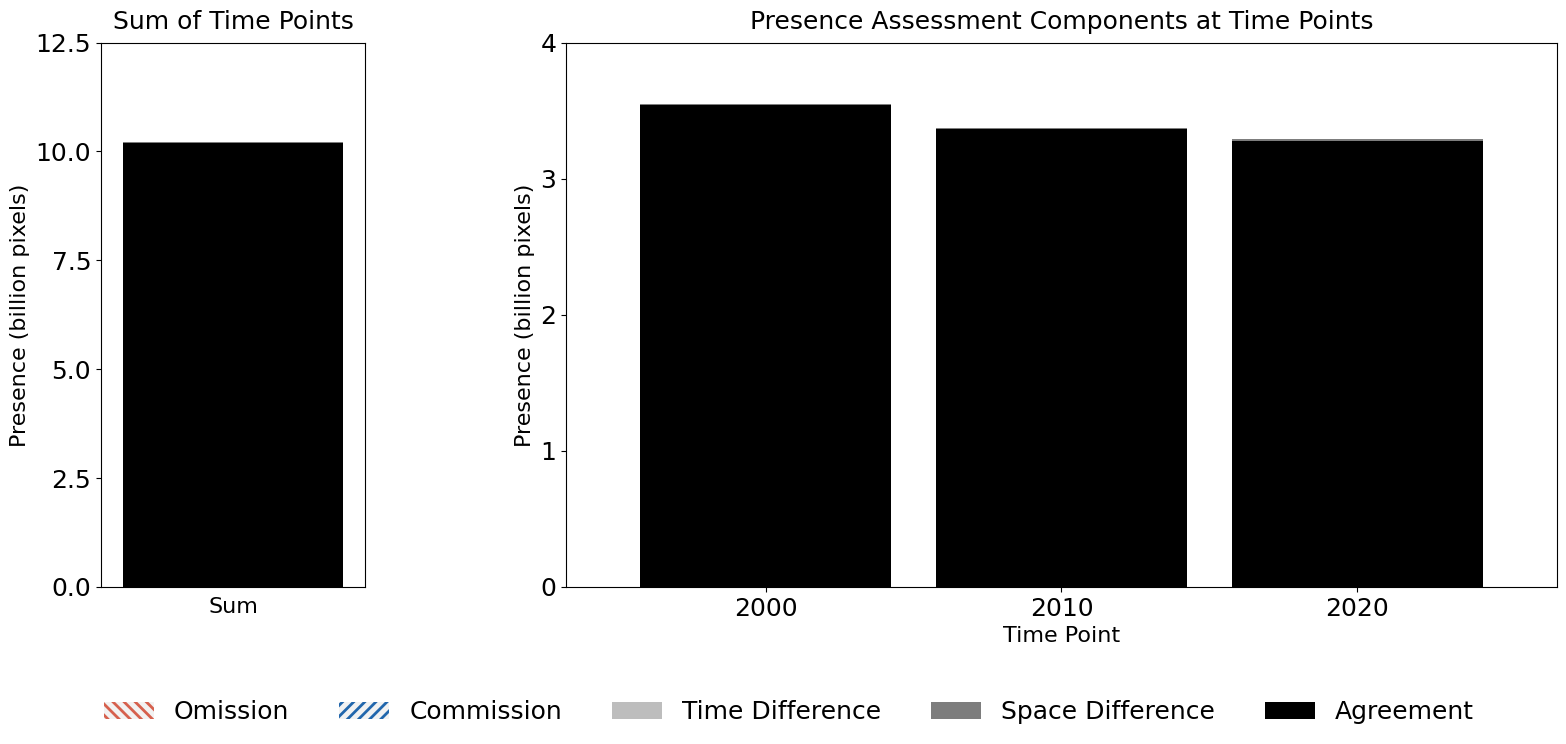

In [44]:
# @title 4.1 Plot Presence Figure
# @markdown This cell plots the Sum of Time Points next to the presence
# @markdown components at each time point, with one legend below both charts.

def _y_axis_label(prefix, unit_name):
    """Build a y-axis label that names area units as area."""
    if RESULT_UNIT == "pixels":
        return f"{prefix} ({unit_name})"
    return f"Area ({unit_name})"


def _x_label_rotation(n_labels):
    """Rotate x labels when there are too many to fit horizontally."""
    return 0 if n_labels <= 12 else 90


def plot_presence_figure(
    csv_path: str,
    output_dir: str,
) -> None:
    """
    Plot the sum chart and the time-point chart in one figure with a
    single legend placed below both charts.

    Parameters
    ----------
    csv_path : str
        Path to the CSV file containing the presence components, in the
        unit set by RESULT_UNIT.
    output_dir : str
        Directory where the 'charts' subfolder will be created and the
        resulting plot will be saved.

    Returns
    -------
    None
    """
    df = pd.read_csv(csv_path)

    order_a = ['Agreement', 'Space Difference', 'Time Difference', 'Commission', 'Omission']
    order_b = ['Agreement', 'Space Difference', 'Commission', 'Omission']
    legend_order = ['Omission', 'Commission', 'Time Difference', 'Space Difference', 'Agreement']

    df_a = df.loc[df['Year'] == 'Total'].set_index('Year')[order_a]
    df_b = df.loc[df['Year'] != 'Total'].set_index('Year')[order_b]

    # Scale large values, such as millions of pixels, for readable ticks.
    scale_factor, unit_name = _scale_dynamic(
        max(df_a.sum(axis=1).max(), df_b.sum(axis=1).max())
    )
    df_a = df_a / scale_factor
    df_b = df_b / scale_factor
    y_label = _y_axis_label("Presence", unit_name)

    # Each entry is (fill color, hatch pattern, hatch color).
    stripe_background = '#F2F2F2'
    style = {
        'Agreement':        ('#000000', None, None),
        'Space Difference': ('#7D7D7D', None, None),
        'Time Difference':  ('#BDBDBD', None, None),
        'Commission':       (stripe_background, '/' * 3, '#2166ac'),
        'Omission':         (stripe_background, '\\' * 3, '#d6604d'),
    }

    def apply_colored_hatches(ax, order):
        """Draw colored hatch lines on the striped components."""
        for container, name in zip(ax.containers, order):
            _, pattern, hatch_color = style[name]
            if pattern:
                for patch in container.patches:
                    patch.set_hatch(pattern)
                    patch.set_edgecolor(hatch_color)
                    patch.set_linewidth(0)

    with plt.rc_context({'hatch.linewidth': 2.0}):
        fig, (ax_a, ax_b) = plt.subplots(
            1, 2,
            figsize=(16, 8),
            gridspec_kw={'width_ratios': [1.6, 6], 'wspace': 0.32},
        )
        fig.subplots_adjust(
            left=0.07,
            right=0.98,
            top=0.90,
            bottom=0.22
        )

        # Sum across time points.
        df_a.plot(
            kind='bar', stacked=True, ax=ax_a,
            color=[style[c][0] for c in order_a],
            edgecolor='none', linewidth=0, width=1.0, legend=False,
        )
        apply_colored_hatches(ax_a, order_a)

        ax_a.set_xlim(-0.6, 0.6)
        top_a = df_a.sum(axis=1).max()
        ticks_a = _fixed_step_yticks(top_a)
        ax_a.set_ylim(0, max(top_a * 1.02, ticks_a[-1]))
        ax_a.set_yticks(ticks_a)
        ax_a.set_title(
            'Sum of Time Points',
            fontsize=18,
            pad=10
        )
        ax_a.set_ylabel(
            y_label,
            fontsize=16
        )
        ax_a.set_xlabel('')
        ax_a.set_xticklabels(
            ['Sum'],
            fontsize=16,
            rotation=0
        )
        ax_a.tick_params(bottom=False)
        ax_a.tick_params(
            axis='y',
            which='major',
            labelsize=18
        )

        # Presence at each time point.
        df_b.plot(
            kind='bar', stacked=True, ax=ax_b,
            color=[style[c][0] for c in order_b],
            edgecolor='none', linewidth=0, width=0.85, legend=False,
        )
        apply_colored_hatches(ax_b, order_b)

        top_b = df_b.sum(axis=1).max()
        ticks_b = _fixed_step_yticks(top_b)
        ax_b.set_ylim(0, max(top_b * 1.02, ticks_b[-1]))
        ax_b.set_yticks(ticks_b)
        ax_b.set_title(
            'Presence Assessment Components at Time Points',
            fontsize=18,
            pad=10
        )
        ax_b.set_xlabel(
            'Time Point',
            fontsize=16
        )
        ax_b.set_ylabel(
            y_label,
            fontsize=16
        )
        ax_b.set_xticks(range(len(df_b)))
        ax_b.set_xticklabels(
            df_b.index.astype(str).tolist(),
            rotation=_x_label_rotation(len(df_b)),
        )
        ax_b.tick_params(
            axis='both',
            which='major',
            labelsize=18
        )

        # Shared legend, handles taken from the sum chart, which has all
        # five components.
        handles_a, labels_a = ax_a.get_legend_handles_labels()
        by_label = dict(zip(labels_a, handles_a))
        leg = fig.legend(
            [by_label[l] for l in legend_order],
            legend_order,
            loc='lower center',
            ncol=len(legend_order),
            frameon=False,
            fontsize=18,
            bbox_to_anchor=(0.5, 0.02),
        )
        for patch, lbl in zip(leg.get_patches(), legend_order):
            _, pattern, hatch_color = style[lbl]
            patch.set_linewidth(0)
            if pattern:
                patch.set_hatch(pattern)
                patch.set_edgecolor(hatch_color)

        charts_dir = os.path.join(
            output_dir,
            "charts"
        )
        os.makedirs(
            charts_dir,
            exist_ok=True
        )
        output_file = os.path.join(
            charts_dir,
            "presence_figure.png"
        )
        plt.savefig(
            output_file,
            dpi=300,
            format='png'
        )
        print(f"Chart successfully saved to: {output_file}\n")
        plt.show()


tables_dir = os.path.join(
    output_path,
    "tables"
)
csv_file_path = os.path.join(
    tables_dir,
    "presence_assessment_metrics.csv"
)
plot_presence_figure(
    csv_file_path,
    output_path,
)


## **5. Change Visualization**

This section plots one figure with four charts from the change tables
created in Section 3.2, and one legend below them. Bars above zero are
gains, and bars below zero are losses.

*   **Top row, gross change:** gains and losses are tracked separately,
    so a location that both gains and loses in different time intervals
    is not cancelled out. The left chart shows Sum and Extent. Sum adds up
    the gross change of every time interval, and Extent compares only the
    first and last time point. The difference between Sum and Extent is
    Alternation. The right chart shows each time interval.
*   **Bottom row, quantity change:** gains and losses in the same
    location and time interval cancel out first. Each chart uses the same
    vertical scale as the gross chart above it, so gross and quantity
    change can be compared directly.


Chart successfully saved to: /content/drive/MyDrive/Assessments/compare-time-series/imazon_mapbiomas/output/charts/change_panel.png



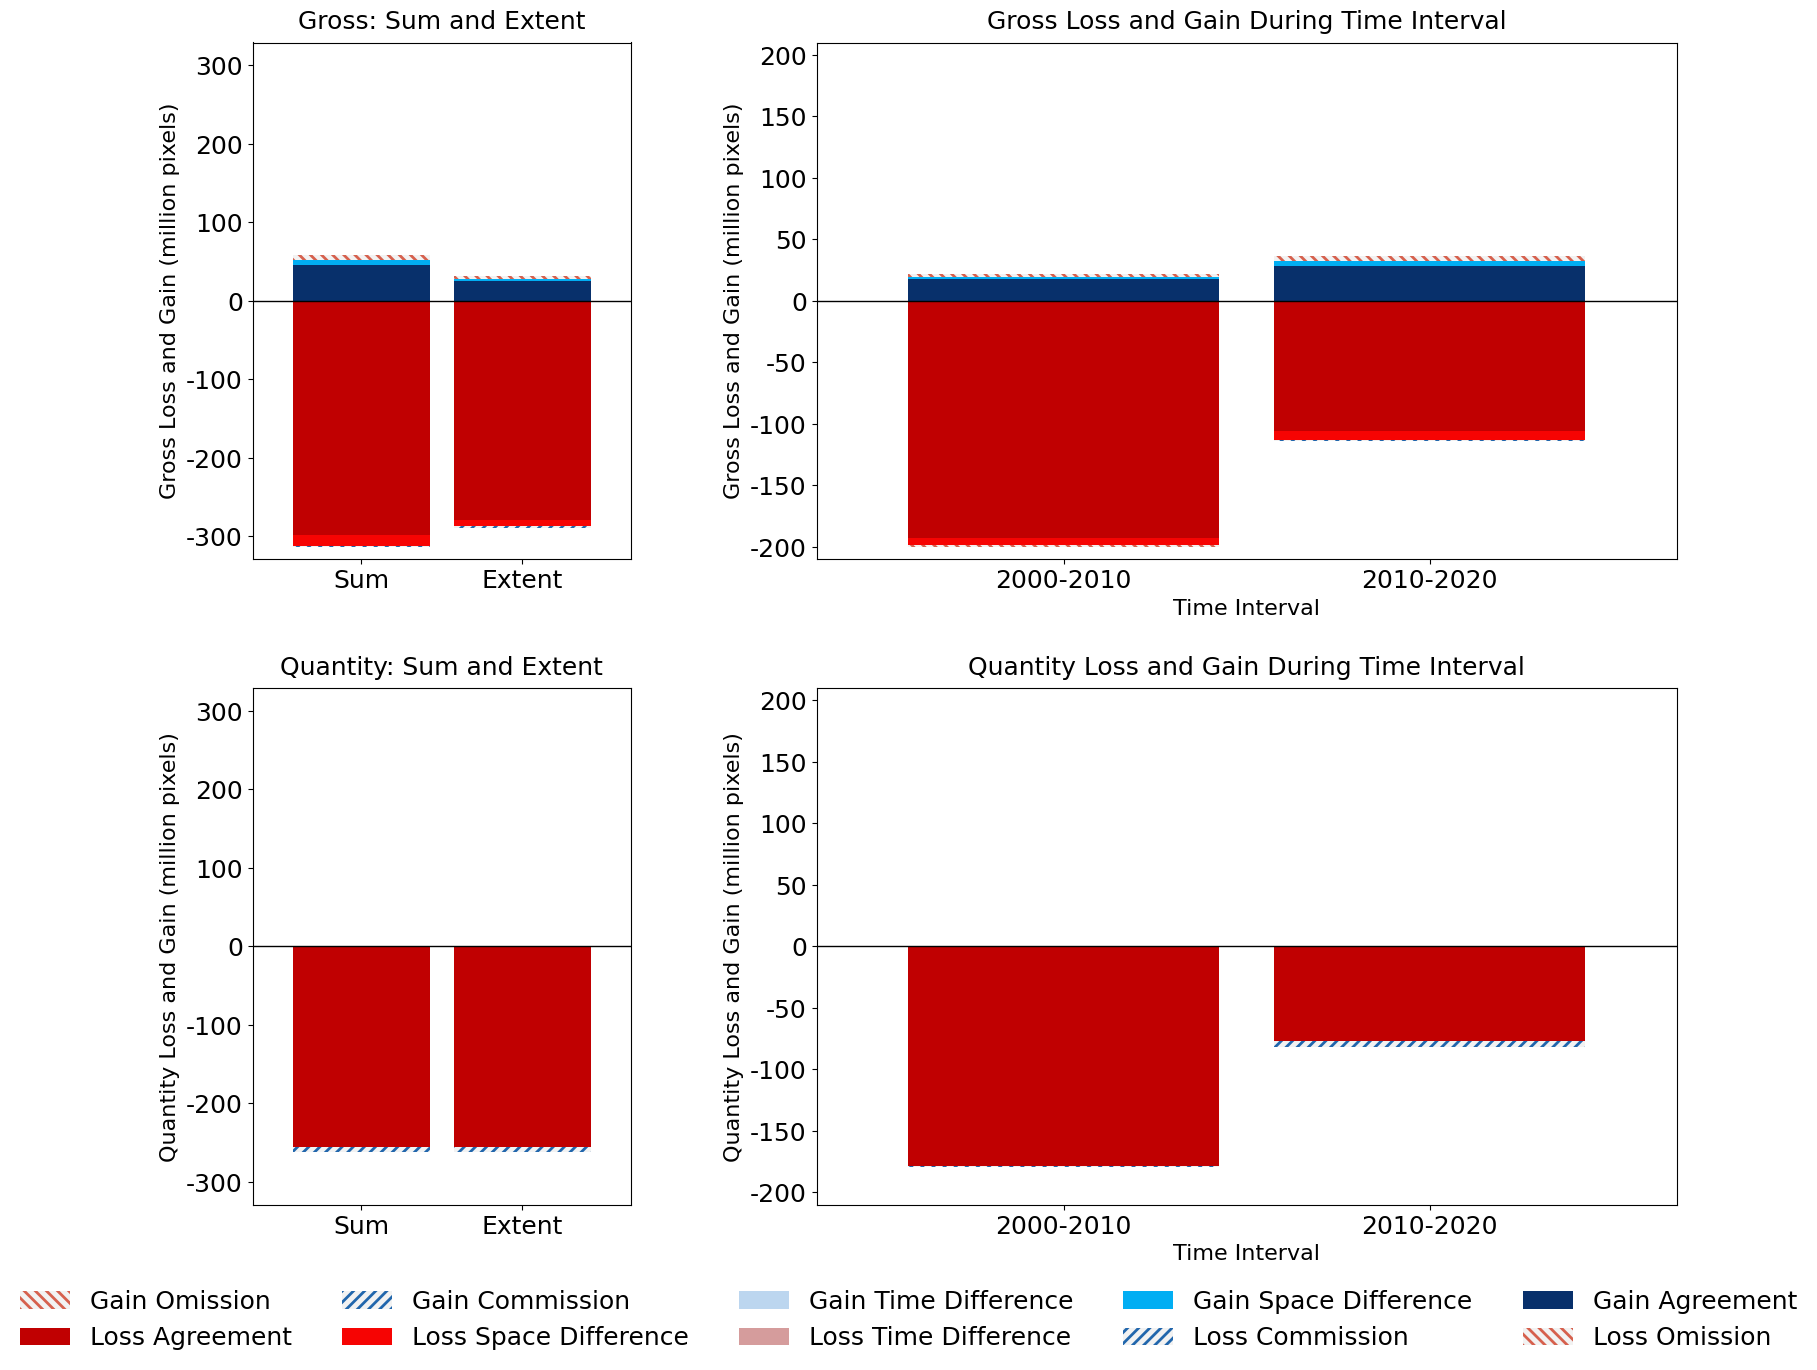

In [45]:
# @title 5.1 Plot Change Figure
# @markdown This cell plots gross change in the top row and quantity change
# @markdown in the bottom row, with one legend below the four charts.

def plot_change_panel(
    net_csv_path: str,
    gross_csv_path: str,
    output_dir: str,
) -> None:
    """
    Combine the four change charts in one figure with a single legend.
    Top row: gross change, Sum and Extent on the left and each time
    interval on the right. Bottom row: quantity change in the same
    layout. The quantity charts use the vertical scale of the gross
    charts in the same column, so rows can be compared directly.

    Parameters
    ----------
    net_csv_path : str
        Path to the CSV file containing the net change components.
    gross_csv_path : str
        Path to the CSV file containing the gross change components.
    output_dir : str
        Directory where the 'charts' subfolder will be created and the
        resulting plot will be saved.

    Returns
    -------
    None
    """
    metrics_order = [
        'Agreement',
        'Space Difference',
        'Time Difference',
        'Commission',
        'Omission',
    ]
    sum_ext = ['Total_Sum', 'Temporal_Extent']

    def load(path):
        d = pd.read_csv(path)
        d[metrics_order] = d[metrics_order].fillna(0)
        return d

    def prepare(d):
        """Return gain/loss frames for the intervals and for Sum/Extent."""
        d = d.copy()
        d.loc[d['Change_Type'] == 'Loss', metrics_order] *= -1  # losses below zero

        d_int = d[~d['Time_Interval'].isin(sum_ext)].copy()
        d_int['Time Difference'] = 0.0  # shown only in the Sum/Extent charts
        d_se = d[d['Time_Interval'].isin(sum_ext)].copy()

        def split(x, order=None):
            g = x[x['Change_Type'] == 'Gain'].set_index('Time_Interval')[metrics_order]
            l = x[x['Change_Type'] == 'Loss'].set_index('Time_Interval')[metrics_order]
            if order:
                g, l = g.reindex(order), l.reindex(order)
            else:
                l = l.reindex(g.index)
            return g, l

        g_int, l_int = split(d_int)
        g_se, l_se = split(d_se, sum_ext)
        names = {'Total_Sum': 'Sum', 'Temporal_Extent': 'Extent'}
        return g_int, l_int, g_se.rename(index=names), l_se.rename(index=names)

    gross = prepare(load(gross_csv_path))
    net = prepare(load(net_csv_path))

    def peak(g, l):
        return max(g.sum(axis=1).max(), l.abs().sum(axis=1).max())

    # Reference peaks from the gross results, scaled for readable ticks.
    peak_int, peak_se = peak(gross[0], gross[1]), peak(gross[2], gross[3])
    scale_factor, unit_name = _scale_dynamic(max(peak_int, peak_se))
    peak_int, peak_se = peak_int / scale_factor, peak_se / scale_factor
    gross = [f / scale_factor for f in gross]
    net = [f / scale_factor for f in net]

    # Striped components use the same light background and hatch colors
    # as the presence figure: Omission in orange, Commission in blue.
    stripe_background = '#F2F2F2'
    gain_colors = {
        'Agreement':        '#08306B',
        'Space Difference': '#01AEF3',
        'Time Difference':  '#BCD6EF',
        'Commission':       stripe_background,
        'Omission':         stripe_background,
    }
    loss_colors = {
        'Agreement':        '#C00001',
        'Space Difference': '#F60403',
        'Time Difference':  '#D59C9C',
        'Commission':       stripe_background,
        'Omission':         stripe_background,
    }
    hatch_by_label = {
        'Agreement':        None,
        'Space Difference': None,
        'Time Difference':  None,
        'Commission':       '/' * 3,
        'Omission':         '\\' * 3,
    }
    hatch_color = {
        'Commission': '#2166ac',
        'Omission':   '#d6604d',
    }
    colors_gain = [gain_colors[l] for l in metrics_order]
    colors_loss = [loss_colors[l] for l in metrics_order]

    def apply_colored_hatches(ax):
        """Draw colored hatch lines on the striped components."""
        for container, name in zip(ax.containers, metrics_order + metrics_order):
            if hatch_by_label[name]:
                for bar in container.patches:
                    bar.set_hatch(hatch_by_label[name])
                    bar.set_edgecolor(hatch_color[name])
                    bar.set_linewidth(0)

    # Rotated interval labels need more room between and below the rows.
    rotated = _x_label_rotation(len(gross[0])) == 90
    with plt.rc_context({'hatch.linewidth': 2.0}):
        fig, axes = plt.subplots(
            2, 2,
            figsize=(16, 17 if rotated else 14),
            gridspec_kw={
                'width_ratios': [2.2, 5],
                'wspace': 0.3,
                'hspace': 0.6 if rotated else 0.25,
            },
        )
        fig.subplots_adjust(
            left=0.09,
            right=0.98,
            top=0.95,
            bottom=0.2 if rotated else 0.12
        )

        def draw(ax, g, l, ref_peak, y_label, title, xlabel=''):
            g.plot(kind='bar', stacked=True, ax=ax, color=colors_gain,
                   edgecolor='none', linewidth=0, width=0.85, legend=False)
            l.plot(kind='bar', stacked=True, ax=ax, color=colors_loss,
                   edgecolor='none', linewidth=0, width=0.85, legend=False)
            apply_colored_hatches(ax)

            pos_ticks = _fixed_step_yticks(ref_peak)
            ax.set_yticks(np.concatenate([-pos_ticks[::-1], pos_ticks[1:]]))
            ax.set_ylim(-ref_peak * 1.05, ref_peak * 1.05)
            ax.axhline(0, color='black', linewidth=1)
            ax.set_title(
                title,
                fontsize=18,
                pad=10
            )
            ax.set_ylabel(
                y_label,
                fontsize=16
            )
            ax.set_xlabel(
                xlabel,
                fontsize=16
            )
            ax.tick_params(
                axis='both',
                which='major',
                labelsize=18
            )
            ax.tick_params(
                axis='x',
                labelrotation=_x_label_rotation(len(g)),
            )
            ax.grid(False)
            ax.yaxis.set_major_formatter(
                ticker.FuncFormatter(lambda x, pos: "0" if x == 0 else f"{x:g}")
            )

        gross_y = f"Gross Loss and Gain ({unit_name})"
        net_y = f"Quantity Loss and Gain ({unit_name})"

        draw(axes[0, 0], gross[2], gross[3], peak_se, gross_y,
             'Gross: Sum and Extent')
        draw(axes[0, 1], gross[0], gross[1], peak_int, gross_y,
             'Gross Loss and Gain During Time Interval', xlabel='Time Interval')
        draw(axes[1, 0], net[2], net[3], peak_se, net_y,
             'Quantity: Sum and Extent')
        draw(axes[1, 1], net[0], net[1], peak_int, net_y,
             'Quantity Loss and Gain During Time Interval', xlabel='Time Interval')

        # Shared legend: row 1 follows the gain bars from top to bottom,
        # row 2 follows the loss bars from top to bottom.
        gain_order = ['Omission', 'Commission', 'Time Difference', 'Space Difference', 'Agreement']
        loss_order = ['Agreement', 'Space Difference', 'Time Difference', 'Commission', 'Omission']

        def patch(kind, lbl):
            colors = gain_colors if kind == 'Gain' else loss_colors
            h = hatch_by_label[lbl]
            return mpatches.Patch(
                facecolor=colors[lbl],
                hatch=h,
                edgecolor=hatch_color[lbl] if h else 'none',
                linewidth=0,
                label=f"{kind} {lbl}",
            )

        rows = [
            [patch('Gain', l) for l in gain_order],
            [patch('Loss', l) for l in loss_order],
        ]
        # matplotlib fills legend columns first, so interleave the two rows.
        flat = [h for pair in zip(*rows) for h in pair]
        fig.legend(
            handles=flat,
            loc='lower center',
            ncol=len(gain_order),
            frameon=False,
            fontsize=18,
            bbox_to_anchor=(0.5, 0.0),
        )

        charts_dir = os.path.join(
            output_dir,
            "charts"
        )
        os.makedirs(
            charts_dir,
            exist_ok=True
        )
        output_file = os.path.join(
            charts_dir,
            "change_panel.png"
        )
        plt.savefig(
            output_file,
            dpi=300,
            format='png',
            bbox_inches='tight'
        )
        print(f"Chart successfully saved to: {output_file}\n")
        plt.show()


tables_dir = os.path.join(
    output_path,
    "tables"
)
net_change_csv_path = os.path.join(
    tables_dir,
    "net_change_components.csv"
)
change_csv_path = os.path.join(
    tables_dir,
    "gross_change_components.csv"
)
plot_change_panel(
    net_change_csv_path,
    change_csv_path,
    output_path,
)


## **6. Spatial Comparison Maps**

This section turns the presence and change comparisons into six
pixel-by-pixel maps, so you can see where agreement and difference occur
instead of only how much:

*   **Presence Agreement and Change Agreement:** where Time Series X and Time Series
    Y consistently agree throughout the time series.
*   **Presence Difference and Change Difference:** where one time series
    consistently shows more presence or change than the other, and which
    one.
*   **Presence Temporal Allocation and Change Absolute Difference:** where
    Time Series X and Time Series Y agree on the total amount but disagree
    on when it occurred. These highlight timing mismatches that the totals
    alone would hide.

Each map is saved as a GeoTIFF in `rasters/`, for use in GIS software, and
as a PNG in `maps/`, for quick viewing.


In [46]:
# @title 6.1 Generate Spatial Comparison Maps
# @markdown This cell creates six maps that compare the two time series:
# @markdown 1. Agreement in presence and change.
# @markdown 2. Differences in the amount of presence or change.
# @markdown 3. Differences in the timing of presence or change.
# @markdown
# @markdown The raster maps are saved in the `rasters` folder and visualized
# @markdown in the following cells.

def _compute_equation_block(
    arr_x_t: List[np.ndarray],
    arr_y_t: List[np.ndarray],
    no_data_val: int,
) -> Dict[str, np.ndarray]:
    """
    Computes all six equation-map components (A-F) for one spatial
    block from the same set of already-read arrays, so presence (Eq.
    49-51) and change (Eq. 52-54) never require a second read pass.
    """
    valid = np.ones_like(
        arr_x_t[0],
        dtype=bool,
    )
    for ax, ay in zip(arr_x_t, arr_y_t):
        valid &= (ax != no_data_val) & (ay != no_data_val)

    # 1. Calculate presence agreement, amount differences, and timing differences.
    A = np.zeros_like(
        arr_x_t[0],
        dtype=np.int32,
    )
    B = np.zeros_like(
        arr_x_t[0],
        dtype=np.int32,
    )
    sum_abs = np.zeros_like(
        arr_x_t[0],
        dtype=np.int32,
    )
    for ax, ay in zip(arr_x_t, arr_y_t):
        A += np.minimum(ax, ay)
        diff = ay - ax
        B += diff
        sum_abs += np.abs(diff)
    C = sum_abs - np.abs(B)

    # 2. Calculate change agreement, amount differences, and timing differences.
    D = np.zeros_like(
        arr_x_t[0],
        dtype=np.int32,
    )
    abs_diff_sum = np.zeros_like(
        arr_x_t[0],
        dtype=np.int32,
    )
    x_prev, y_prev = arr_x_t[0], arr_y_t[0]
    for ax, ay in zip(arr_x_t[1:], arr_y_t[1:]):
        dx = ax - x_prev
        dy = ay - y_prev
        gain_x, gain_y = np.maximum(0, dx), np.maximum(0, dy)
        loss_x, loss_y = np.minimum(0, dx), np.minimum(0, dy)
        gh = np.minimum(gain_x, gain_y)
        lh = np.maximum(loss_x, loss_y)
        D += (gh - lh)
        abs_diff_sum += np.abs(dy - dx)
        x_prev, y_prev = ax, ay
    E = (y_prev - arr_y_t[0]) - (x_prev - arr_x_t[0])
    F = abs_diff_sum - np.abs(E)

    return {
        "A": np.where(valid, A, no_data_val).astype(np.int16),
        "B": np.where(valid, B, no_data_val).astype(np.int16),
        "C": np.where(valid, C, no_data_val).astype(np.int16),
        "D": np.where(valid, D, no_data_val).astype(np.int16),
        "E": np.where(valid, E, no_data_val).astype(np.int16),
        "F": np.where(valid, F, no_data_val).astype(np.int16),
    }


def _read_and_compute_equation_block(
    x_paths: Tuple[str, ...],
    y_paths: Tuple[str, ...],
    window: Window,
    no_data_val: int,
) -> Tuple[Window, Dict[str, np.ndarray]]:
    """Worker: reads one block from every X/Y raster (T+1 each) ONCE
    and computes all six equation components. Runs in a thread pool —
    the disk read (via GDAL) releases the GIL, so threads overlap I/O
    wait time across blocks."""
    srcs_x, srcs_y = _get_thread_datasets_eq(
        x_paths,
        y_paths,
    )

    # 3. Read each raster block as signed numbers so calculated differences
    # can correctly include negative values.
    arr_x_t = [
        s.read(1, window=window).astype(np.int32) for s in srcs_x
    ]
    arr_y_t = [
        s.read(1, window=window).astype(np.int32) for s in srcs_y
    ]

    return window, _compute_equation_block(
        arr_x_t,
        arr_y_t,
        no_data_val,
    )


def generate_equation_maps(
    ts_x_paths: List[str],
    ts_y_paths: List[str],
    output_dir: str,
    no_data_val: int = no_data_value,
    max_workers: int = 8,
) -> None:
    """
    Generates all six equation maps (A-F, Equations 49-54) in a SINGLE
    pass over the raster blocks — presence (49-51) and change (52-54)
    used to be two separate full read-throughs of the same X/Y files;
    now every time point is read once per block and reused for both.

    Block reads run in parallel across `max_workers` threads (I/O-bound
    gain, matters most once rasters reach into the millions of
    pixels); writes stay in the main thread, one per completed block,
    which is safe since each write targets its own window regardless
    of completion order.

    Output files are named to match the equation table's columns
    (eq49_presence_agreement.tif, eq50_presence_difference.tif, ...,
    eq54_change_temporal_allocation.tif) instead of the old
    presence_map_*/change_map_* naming. Overviews are built for each
    output so downstream decimated reads (map plotting) stay fast
    regardless of raster size.

    Parameters
    ----------
    ts_x_paths : List[str]
        List of file paths for Time Series X.
    ts_y_paths : List[str]
        List of file paths for Time Series Y.
    output_dir : str
        Directory where the output maps will be saved.
    no_data_val : int, optional
        Pixel value indicating no data, by default no_data_value.
    max_workers : int, optional
        Number of threads used to read/process raster blocks in
        parallel. Default is 8.

    Returns
    -------
    None
    """
    maps_dir = os.path.join(
        output_dir,
        "rasters",
    )
    os.makedirs(
        maps_dir,
        exist_ok=True,
    )

    output_names = {
        "A": "eq49_presence_agreement.tif",
        "B": "eq50_presence_difference.tif",
        "C": "eq51_presence_temporal_allocation.tif",
        "D": "eq52_change_agreement.tif",
        "E": "eq53_change_difference.tif",
        "F": "eq54_change_temporal_allocation.tif",
    }
    paths = {
        k: os.path.join(maps_dir, v)
        for k, v in output_names.items()
    }

    x_paths_t = tuple(ts_x_paths)
    y_paths_t = tuple(ts_y_paths)

    with ExitStack() as stack:
        srcs_x = [
            stack.enter_context(rasterio.open(p)) for p in ts_x_paths
        ]
        srcs_y = [
            stack.enter_context(rasterio.open(p)) for p in ts_y_paths
        ]
        meta = srcs_x[0].meta.copy()
        windows = _resolve_windows_eq(srcs_x + srcs_y)

    meta.update({
        'dtype': rasterio.int16,
        'nodata': no_data_val,
        'compress': 'deflate',
    })

    # 4. Prepare the six output raster files and process the comparison.
    keys = ["A", "B", "C", "D", "E", "F"]

    with ExitStack() as stack:
        dsts = {
            k: stack.enter_context(
                rasterio.open(paths[k], 'w', **meta)
            )
            for k in keys
        }

        # Keep at most max_pending blocks in memory at once, so finished
        # blocks do not pile up while the main thread writes.
        max_pending = max_workers * 2
        window_iter = iter(windows)

        def _submit_next(executor, pending):
            window = next(window_iter, None)
            if window is not None:
                pending.add(
                    executor.submit(
                        _read_and_compute_equation_block,
                        x_paths_t,
                        y_paths_t,
                        window,
                        no_data_val,
                    )
                )

        with ThreadPoolExecutor(max_workers=max_workers) as executor:
            pending = set()
            for _ in range(max_pending):
                _submit_next(executor, pending)

            with tqdm(
                total=len(windows),
                desc="Generating comparison maps",
            ) as pbar:
                while pending:
                    done, pending = wait(
                        pending,
                        return_when=FIRST_COMPLETED,
                    )
                    for future in done:
                        window, out = future.result()
                        for k in keys:
                            dsts[k].write(out[k], 1, window=window)
                        pbar.update(1)
                        _submit_next(executor, pending)

        # 5. Create smaller internal previews to make later map display faster.
        raster_width, raster_height = meta['width'], meta['height']
        candidate_levels = [2, 4, 8, 16]
        valid_levels = [
            lvl for lvl in candidate_levels
            if (raster_width // lvl) >= 2 and (raster_height // lvl) >= 2
        ]

        if valid_levels:
            for k in keys:
                dsts[k].build_overviews(
                    valid_levels,
                    rasterio.enums.Resampling.nearest,
                )
                dsts[k].update_tags(
                    ns='rio_overview',
                    resampling='nearest',
                )
        else:
            print(
                f"  [note] Raster is {raster_width}x{raster_height} pixels — too "
                f"small for any overview level to be useful; skipping."
            )

    # 6. Show where the completed raster maps were saved.
    print("\nRaster maps saved to:")
    for path in paths.values():
        print(f"  - {path}")
    print("Spatial comparison raster maps saved successfully.")


# Execute the function
generate_equation_maps(
    ts_x_paths=time_series_x,
    ts_y_paths=time_series_y,
    output_dir=output_path,
    no_data_val=no_data_value,
)

Generating comparison maps:   0%|          | 0/37909 [00:00<?, ?it/s]


Raster maps saved to:
  - /content/drive/MyDrive/Assessments/compare-time-series/imazon_mapbiomas/output/rasters/eq49_presence_agreement.tif
  - /content/drive/MyDrive/Assessments/compare-time-series/imazon_mapbiomas/output/rasters/eq50_presence_difference.tif
  - /content/drive/MyDrive/Assessments/compare-time-series/imazon_mapbiomas/output/rasters/eq51_presence_temporal_allocation.tif
  - /content/drive/MyDrive/Assessments/compare-time-series/imazon_mapbiomas/output/rasters/eq52_change_agreement.tif
  - /content/drive/MyDrive/Assessments/compare-time-series/imazon_mapbiomas/output/rasters/eq53_change_difference.tif
  - /content/drive/MyDrive/Assessments/compare-time-series/imazon_mapbiomas/output/rasters/eq54_change_temporal_allocation.tif
Spatial comparison raster maps saved successfully.


In [47]:
# @title 6.2 Prepare Map Visualization Tools
# @markdown This cell prepares the common display tools used by the six maps below:
# @markdown 1. Load and resize the raster maps for efficient visualization.
# @markdown 2. Apply colors, legends, and labels appropriate to each map.
# @markdown 3. Add coordinates, a north arrow, and a scale bar.
# @markdown 4. Save the final map images in the `maps` folder.
from functools import lru_cache

_geod_wgs84 = Geod(ellps="WGS84")


@lru_cache(
    maxsize=None,
)
def _get_crs_transformer(src_crs_wkt: str):
    """
    Return a cached transformer from the raster CRS to geographic coordinates.

    Parameters
    ----------
    src_crs_wkt : str
        Source coordinate reference system in WKT format.

    Returns
    -------
    pyproj.Transformer
        Transformer configured for the source CRS and EPSG:4326.
    """
    return Transformer.from_crs(
        src_crs_wkt,
        "EPSG:4326",
        always_xy=True,
    )


def compute_display_pixel_size_m(
    raster_path: str,
    downsample_divisor: int,
) -> float:
    """
    Compute horizontal resolution in meters per displayed pixel.

    Only reads the raster's metadata (bounds/CRS/width) — never touches
    pixel data — so this cost is O(1) regardless of raster size. Reuses
    a cached Transformer per CRS and a single shared Geod instance
    instead of rebuilding them on every call.

    Parameters
    ----------
    raster_path : str
        Path to a raster file used to derive spatial extent and CRS.
    downsample_divisor : int
        Integer factor used to downsample the raster width for display.

    Returns
    -------
    float
        Pixel size in meters for the downsampled display grid.
    """
    with rasterio.open(raster_path) as src:
        left, bottom, right, top = src.bounds
        lat_mid_src = (top + bottom) / 2.0
        src_crs_wkt = src.crs.to_wkt()
        src_width = src.width

    to_ll = _get_crs_transformer(src_crs_wkt)
    lon_l, lat_mid = to_ll.transform(
        left,
        lat_mid_src,
    )
    lon_r, _ = to_ll.transform(
        right,
        lat_mid_src,
    )

    _, _, width_m = _geod_wgs84.inv(
        lon_l,
        lat_mid,
        lon_r,
        lat_mid,
    )

    cols_disp = max(1, src_width // downsample_divisor)

    return width_m / cols_disp


def _plot_equation_map(
    output_dir: str,
    nodata_val: int,
    raster_filename: str,
    title: str,
    legend_title: str,
    output_png_name: str,
    colormap_style: str,
    max_display_dim: int = 2000
) -> None:
    """
    Loads one comparison raster, styles it according to its map type,
    adds geographic context, and saves the resulting figure.

    Parameters
    ----------
    output_dir : str
        Directory where the 'rasters' and 'maps' folders are located.
    nodata_val : int
        Pixel value indicating no data.
    raster_filename : str
        Filename of the input raster (inside output_dir/rasters).
    title : str
        Map title.
    legend_title : str
        Legend title.
    output_png_name : str
        Filename for the saved PNG (inside output_dir/maps).
    colormap_style : str
        One of "cividis_agreement", "diverging_redblue", "redyellowgreen",
        "turbo_neg_black" — selects which of the four color schemes
        used for the different comparison map types.
    max_display_dim : int, optional
        Maximum dimension (width or height) in pixels for the display
        grid to optimize RAM usage. Default is 2000.

    Returns
    -------
    None
    """
    rasters_dir = os.path.join(
        output_dir,
        "rasters",
    )
    raster_path = os.path.join(
        rasters_dir,
        raster_filename,
    )

    if not os.path.exists(raster_path):
        raise FileNotFoundError(f"Raster not found: {raster_path}")

    print(f"Reading {title} map for plotting: {raster_path}")

    # 1. Load and resize the selected raster for display.
    with rasterio.open(raster_path) as src:
        scale_factor = max_display_dim / max(
            src.width,
            src.height,
        )
        if scale_factor > 1:
            scale_factor = 1.0

        out_shape = (
            int(src.height * scale_factor),
            int(src.width * scale_factor)
        )

        print(
            f"Loading raster with downsampling factor: "
            f"{scale_factor:.2f}"
        )

        data = src.read(
            1,
            out_shape=out_shape,
            resampling=rasterio.enums.Resampling.nearest
        )


        src_crs = src.crs
        transform = src.transform
        data_masked = np.ma.masked_equal(data, nodata_val)

    pixel_size_m = compute_display_pixel_size_m(
        raster_path=raster_path,
        downsample_divisor=(
            int(1 / scale_factor)
            if scale_factor < 1
            else 1
        ),
    )

    # 2. Select colors and legend values for this map type.
    data_max = int(data_masked.max())
    data_min = int(data_masked.min())

    if colormap_style == "cividis_agreement":
        # Agreement map: use a sequential color scale.
        if data_max == 0:
            data_max = 1
        original_cmap = plt.get_cmap("cividis")
        colors_list = ["#c0c0c0"] + [
            original_cmap(i) for i in np.linspace(0, 1, data_max)
        ]
        cmap = ListedColormap(colors_list)
        bounds = np.arange(0, data_max + 2)
        norm = BoundaryNorm(bounds, cmap.N)
        colors_dict = {
            i: cmap(norm(i))
            for i in range(0, data_max + 1)
        }
        present_values = np.unique(data_masked.compressed())
        legend_values = [
            v
            for v in range(0, data_max + 1)
            if v in present_values
        ]

    elif colormap_style == "diverging_redblue":
        # Difference map: use red and blue to show direction and magnitude.
        if data_max < 1:
            data_max = 1
        if data_min > -1:
            data_min = -1

        colors_dict = {0: "#c0c0c0"}
        red_cmap = plt.get_cmap("Reds")
        red_colors = red_cmap(
            np.linspace(0.2, 0.9, abs(data_min))
        )
        for i, val in enumerate(range(-1, data_min - 1, -1)):
            colors_dict[val] = red_colors[i]

        blue_cmap = plt.get_cmap("Blues")
        blue_colors = blue_cmap(
            np.linspace(0.2, 0.9, data_max)
        )
        for i, val in enumerate(range(1, data_max + 1)):
            colors_dict[val] = blue_colors[i]

        all_vals = np.arange(
            data_min,
            data_max + 1,
        )
        colors_list = [
            colors_dict.get(v, "#000000")
            for v in all_vals
        ]
        cmap = ListedColormap(colors_list)
        bounds = np.arange(data_min - 0.5, data_max + 1.5, 1)
        norm = BoundaryNorm(bounds, cmap.N)

        present_values = np.unique(data_masked.compressed())
        legend_values = sorted(present_values, reverse=True)

    elif colormap_style == "redyellowgreen":
        # Temporal allocation map: use a sequential red-yellow-green scale.
        if data_max < 1:
            data_max = 1

        colors_dict = {0: "#c0c0c0"}
        pos_cmap = LinearSegmentedColormap.from_list(
            "red_yellow_green", ["#8b0000", "#ffff00", "#90ee90"]
        )
        for i, val in enumerate(range(1, data_max + 1)):
            frac = i / (data_max - 1) if data_max > 1 else 0.5
            colors_dict[val] = pos_cmap(frac)

        colors_list = [
            colors_dict.get(v, "#000000")
            for v in range(data_max + 1)
        ]
        cmap = ListedColormap(colors_list)
        bounds = np.arange(-0.5, data_max + 1.5, 1)
        norm = BoundaryNorm(bounds, cmap.N)

        present_values = np.unique(data_masked.compressed())
        legend_values = sorted(present_values)

    elif colormap_style == "turbo_neg_black":
        # Change agreement map: distinguish positive and negative change.
        if data_max < 1:
            data_max = 1
        if data_min > 0:
            data_min = 0

        colors_dict = {0: "#c0c0c0"}
        positive_cmap = plt.get_cmap("turbo_r")
        for val in range(1, data_max + 1):
            if data_max <= 1:
                fraction = 0.0
            elif val == 1:
                fraction = 0.0
            elif val == 2:
                fraction = 0.35
            else:
                fraction = 0.35 + 0.65 * (val - 2) / (data_max - 2)
            colors_dict[val] = positive_cmap(fraction)

        if data_min < 0:
            for val in range(data_min, 0):
                colors_dict[val] = "#000000"

        all_vals = np.arange(data_min, data_max + 1)
        colors_list = [
            colors_dict.get(v, "#000000")
            for v in all_vals
        ]
        cmap = ListedColormap(colors_list)
        bounds = np.arange(data_min - 0.5, data_max + 1.5, 1)
        norm = BoundaryNorm(bounds, cmap.N)

        present_values = np.unique(data_masked.compressed())
        legend_values = sorted(present_values)

    else:
        raise ValueError(f"Unknown colormap_style: {colormap_style}")

    # 3. Draw the raster, legend, and map title.
    fig, ax = plt.subplots(
        figsize=(8, 5),
        dpi=300,
    )
    fig.subplots_adjust(
        left=0.1,
        right=0.65,
        top=0.90,
        bottom=0.05,
    )

    ax.imshow(data_masked, cmap=cmap, norm=norm, interpolation="nearest")

    legend_elements = [
        Patch(
            facecolor=colors_dict.get(
                val,
                "#000",
            ),
            edgecolor="none",
            label=str(val),
        ) for val in legend_values
    ]

    legend_columns = max(
        1,
        min(4, int(np.ceil(len(legend_values) / 10))),
    )

    ax.legend(
        handles=legend_elements,
        title=legend_title,
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        frameon=False,
        fontsize=7,
        title_fontsize=9,
        ncol=legend_columns,
        columnspacing=0.8,
        labelspacing=0.4,
        handletextpad=0.4,
        alignment="left",
    )

    # 4. Add geographic context with a scale bar and north arrow.
    # Write the scale bar label in km, whatever SI prefix the bar picks.
    km_per_unit = {
        "mm": 1e-6,
        "cm": 1e-5,
        "m": 1e-3,
        "km": 1,
        "Mm": 1e3,
        "Gm": 1e6,
    }

    def _format_km(value, unit):
        km = value * km_per_unit.get(unit, 1)
        return f"{km:g} km"

    scalebar = ScaleBar(
        pixel_size_m,
        units="m",
        length_fraction=0.35,
        location="lower right",
        box_alpha=0.0,
        scale_formatter=_format_km,
    )
    ax.add_artist(scalebar)

    north_arrow(
        ax,
        location="upper right",
        shadow=False,
        scale=0.3,
        rotation={
            "degrees": None,
            "crs": src_crs,
            "reference": "center",
        },
    )

    # 5. Add geographic coordinates to the axes.
    ax.set_title(
        title,
        fontsize=18,
        pad=5,
    )
    ax.set_aspect("equal")

    to_latlon = Transformer.from_crs(
        src_crs,
        "EPSG:4326",
        always_xy=True,
    )
    height, width = data.shape

    def format_lon(x, pos):
        """
        Format an axis position as longitude in decimal degrees.

        Parameters
        ----------
        x : float
            Display-grid column position.
        pos : int
            Matplotlib tick position index.

        Returns
        -------
        str
            Longitude label with a degree symbol.
        """
        x = np.clip(x, 0, width - 1)
        x_proj, y_proj = rasterio.transform.xy(transform, height // 2, x)
        lon, _ = to_latlon.transform(x_proj, y_proj)
        return f"{lon:.1f}°"

    def format_lat(y, pos):
        """
        Format an axis position as latitude in decimal degrees.

        Parameters
        ----------
        y : float
            Display-grid row position.
        pos : int
            Matplotlib tick position index.

        Returns
        -------
        str
            Latitude label with a degree symbol.
        """
        y = np.clip(y, 0, height - 1)
        x_proj, y_proj = rasterio.transform.xy(transform, y, width // 2)
        _, lat = to_latlon.transform(x_proj, y_proj)
        return f"{lat:.1f}°"

    ax.xaxis.set_major_formatter(FuncFormatter(format_lon))
    ax.yaxis.set_major_formatter(FuncFormatter(format_lat))
    ax.xaxis.set_major_locator(
        mticker.MaxNLocator(nbins=4)
    )
    ax.yaxis.set_major_locator(
        mticker.MaxNLocator(nbins=6)
    )
    ax.tick_params(axis="both", labelsize=7, pad=4)
    plt.setp(ax.get_yticklabels(), rotation=90, va="center")

    # 6. Save the image and release temporary data.
    maps_dir = os.path.join(
        output_dir,
        "maps",
    )
    os.makedirs(
        maps_dir,
        exist_ok=True,
    )
    output_figure_path = os.path.join(
        maps_dir,
        output_png_name,
    )

    plt.savefig(output_figure_path, dpi=300, format="png")
    plt.show()

    print(
        f"Map successfully saved to: {output_figure_path}"
    )

    del data
    del data_masked
    gc.collect()

Reading Presence Agreement map for plotting: /content/drive/MyDrive/Assessments/compare-time-series/imazon_mapbiomas/output/rasters/eq49_presence_agreement.tif
Loading raster with downsampling factor: 0.02


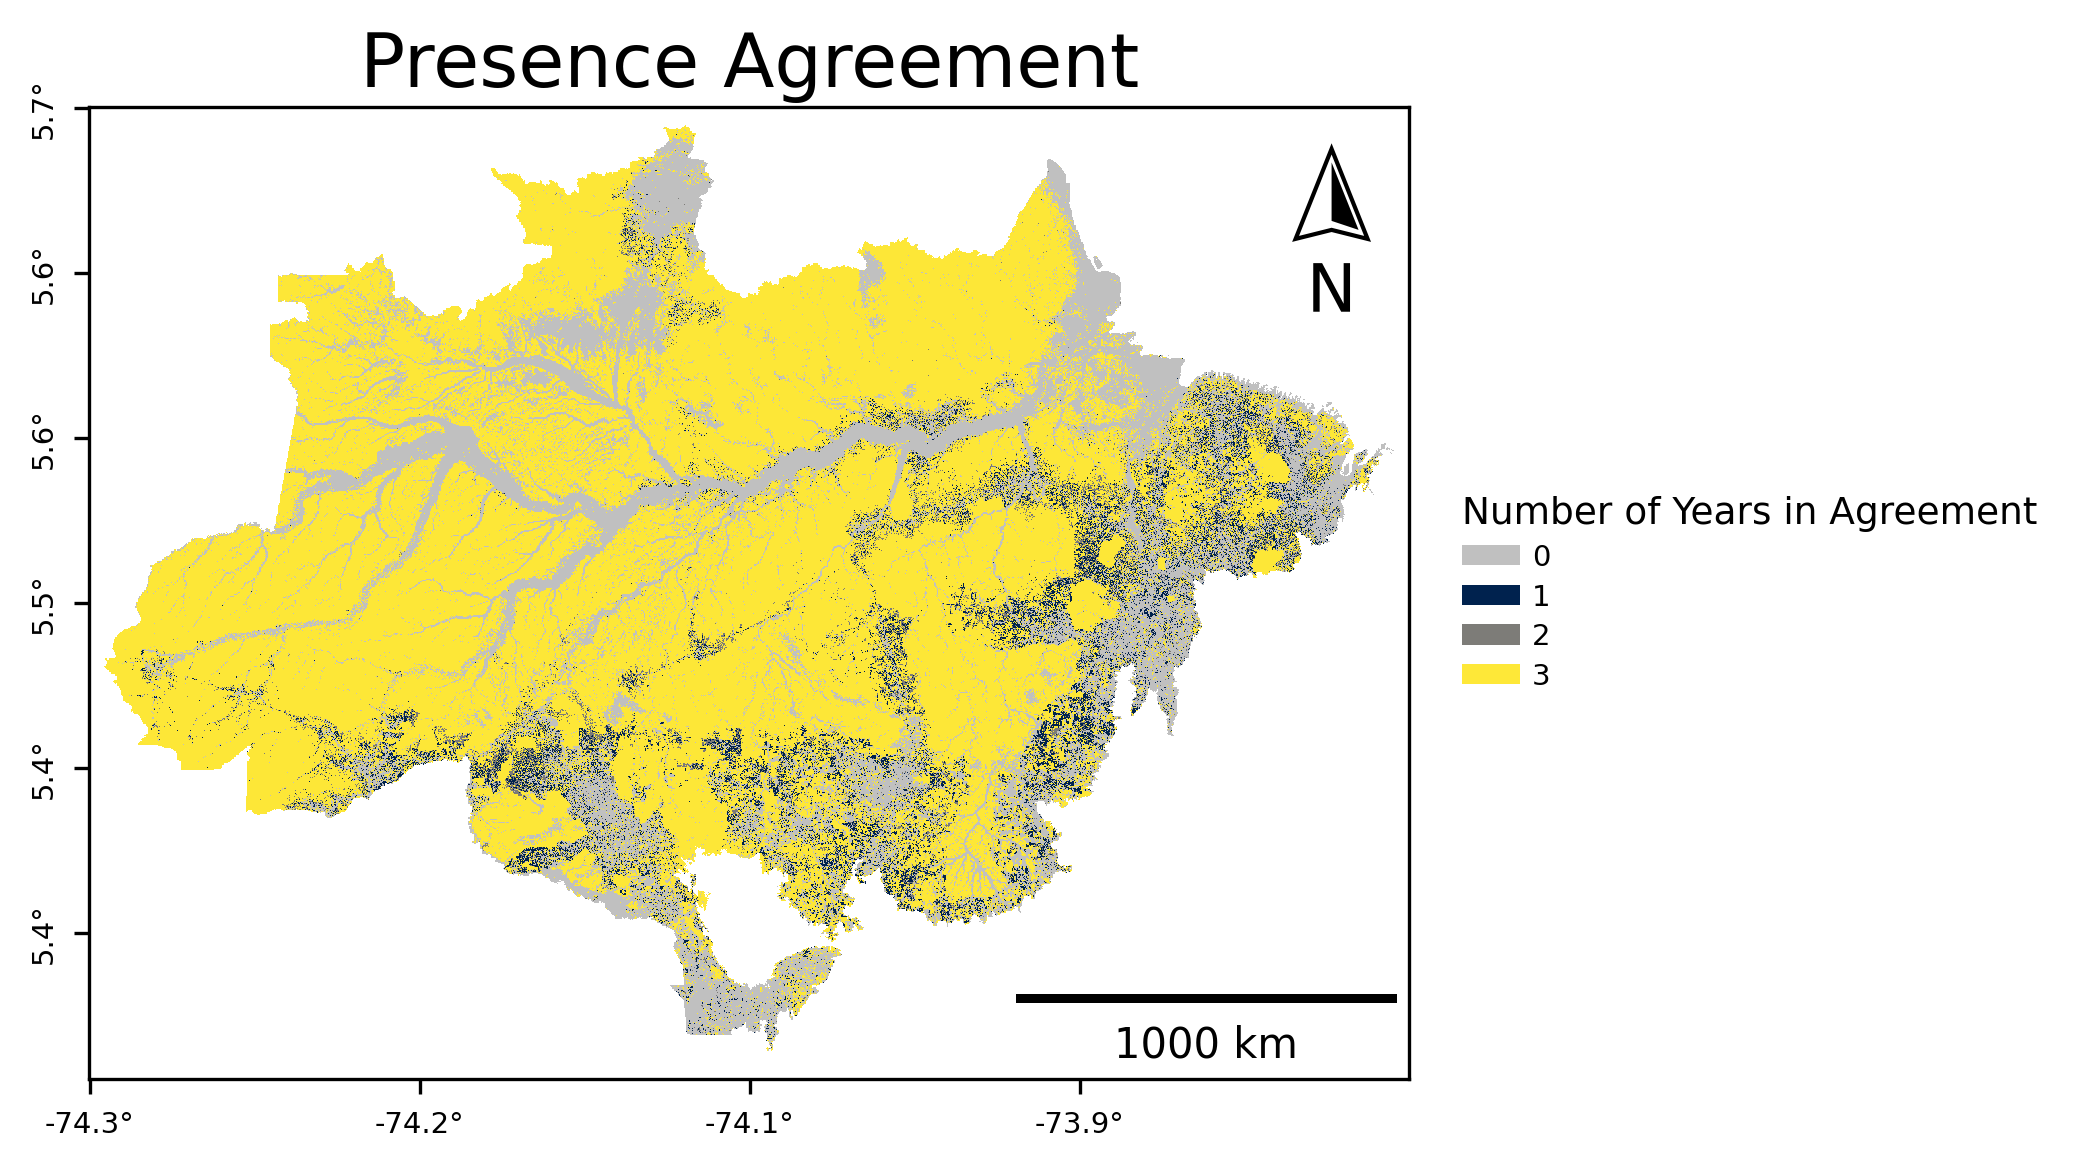

Map successfully saved to: /content/drive/MyDrive/Assessments/compare-time-series/imazon_mapbiomas/output/maps/map_presence_agreement.png


In [48]:
# @title 6.3 Plot Presence Agreement
_plot_equation_map(
    output_dir=output_path,
    nodata_val=no_data_value,
    raster_filename="eq49_presence_agreement.tif",
    title="Presence Agreement",
    legend_title="Number of Years in Agreement",
    output_png_name="map_presence_agreement.png",
    colormap_style="cividis_agreement",
)


Reading Presence Difference map for plotting: /content/drive/MyDrive/Assessments/compare-time-series/imazon_mapbiomas/output/rasters/eq50_presence_difference.tif
Loading raster with downsampling factor: 0.02


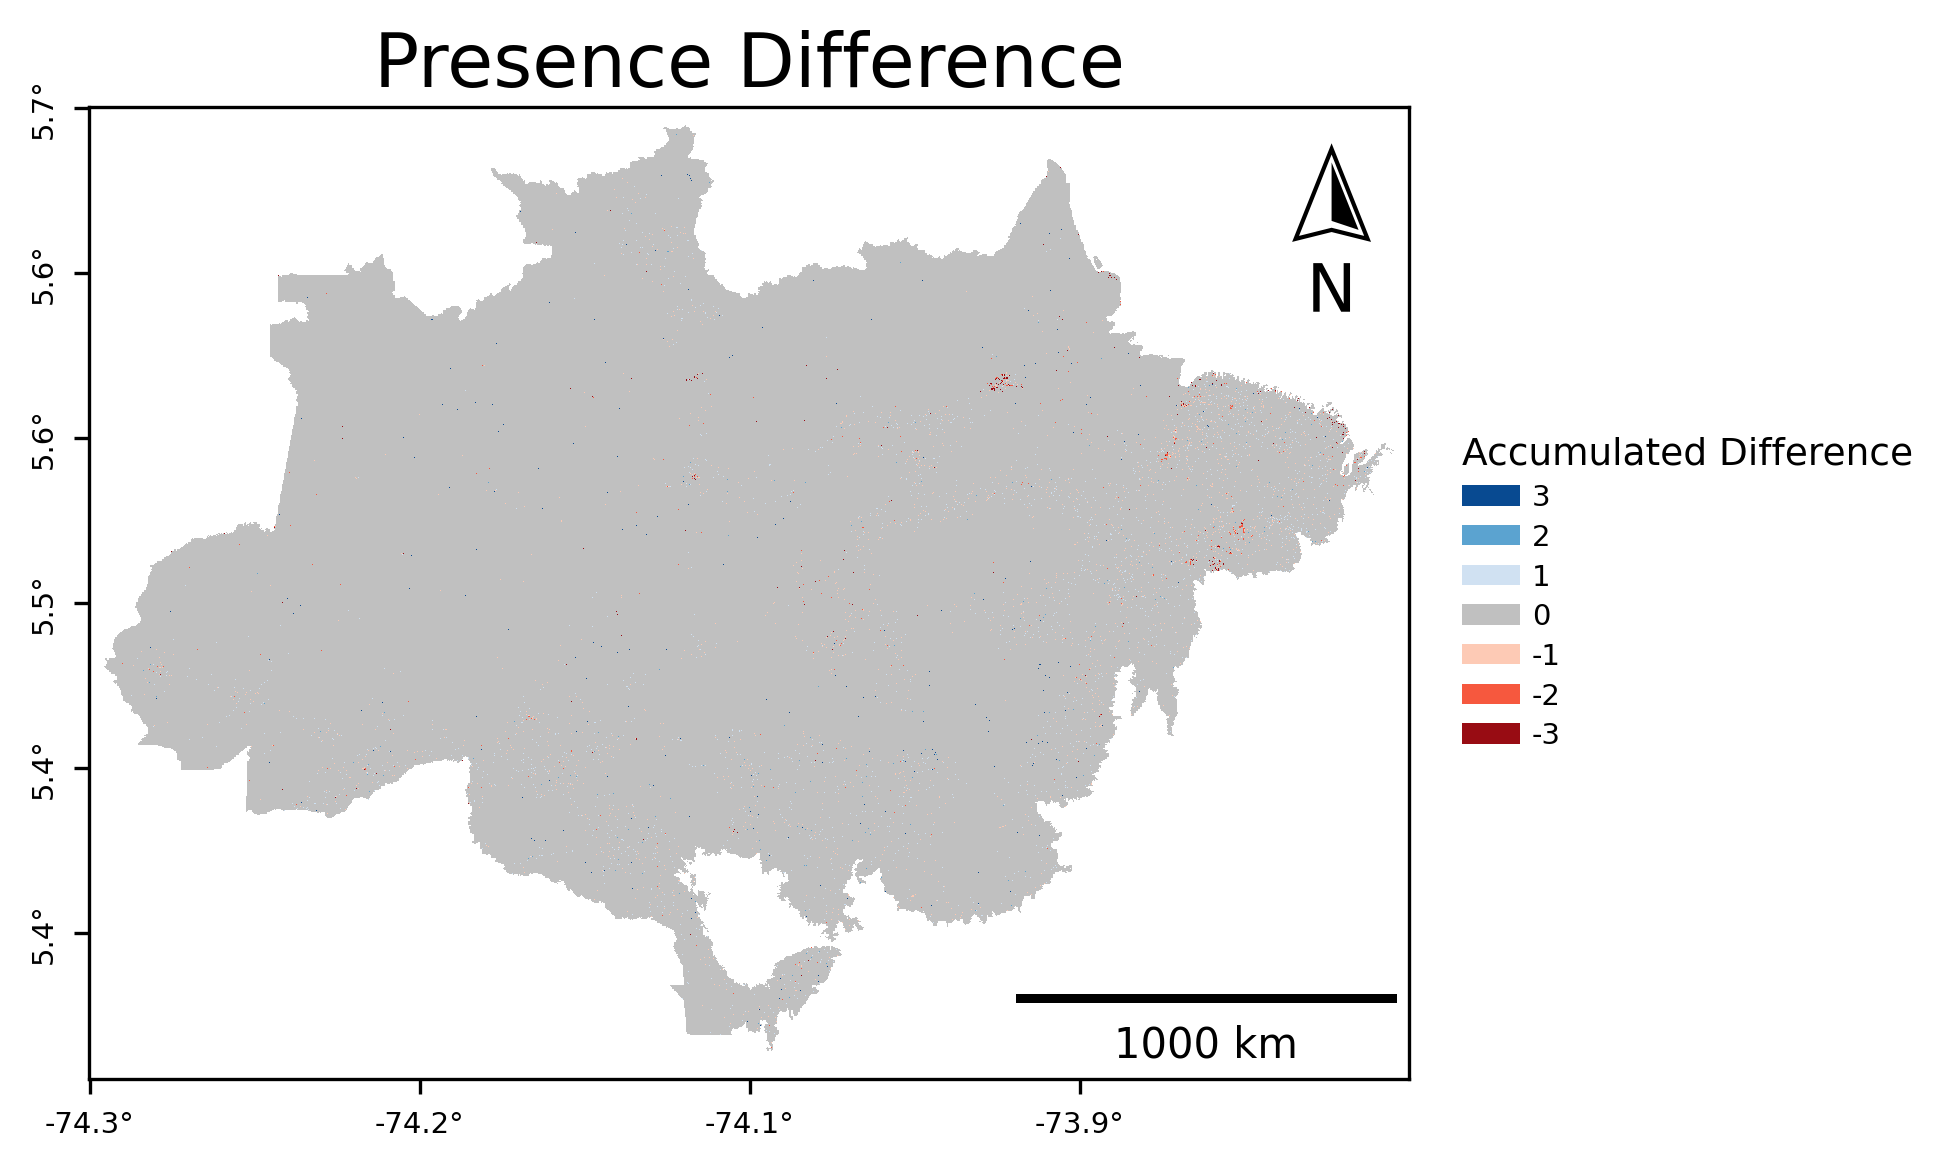

Map successfully saved to: /content/drive/MyDrive/Assessments/compare-time-series/imazon_mapbiomas/output/maps/map_presence_difference.png


In [49]:
# @title 6.4 Plot Presence Difference
_plot_equation_map(
    output_dir=output_path,
    nodata_val=no_data_value,
    raster_filename="eq50_presence_difference.tif",
    title="Presence Difference",
    legend_title="Accumulated Difference",
    output_png_name="map_presence_difference.png",
    colormap_style="diverging_redblue",
)


Reading Temporal Allocation Difference map for plotting: /content/drive/MyDrive/Assessments/compare-time-series/imazon_mapbiomas/output/rasters/eq51_presence_temporal_allocation.tif
Loading raster with downsampling factor: 0.02


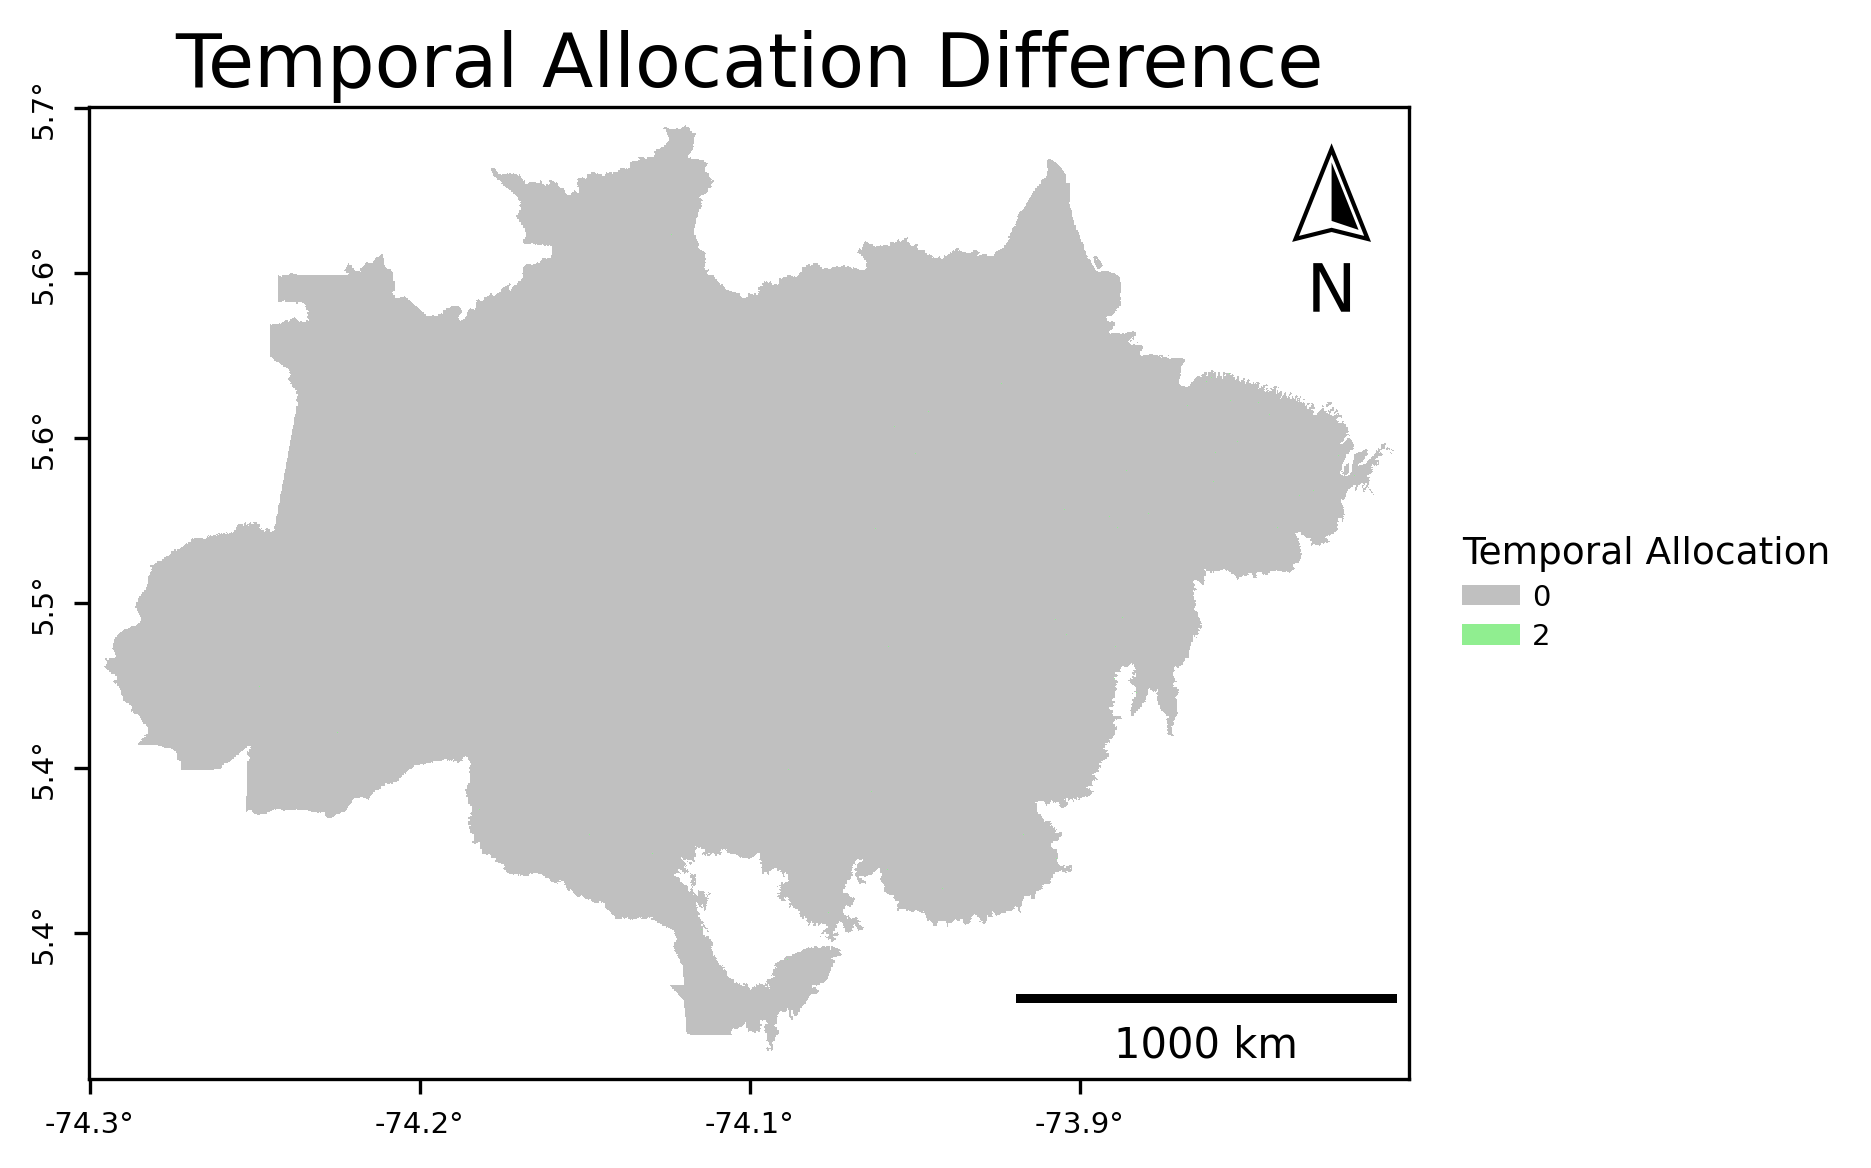

Map successfully saved to: /content/drive/MyDrive/Assessments/compare-time-series/imazon_mapbiomas/output/maps/map_presence_temporal_allocation.png


In [50]:
# @title 6.5 Plot Temporal Allocation Difference for Presence
_plot_equation_map(
    output_dir=output_path,
    nodata_val=no_data_value,
    raster_filename="eq51_presence_temporal_allocation.tif",
    title="Temporal Allocation Difference",
    legend_title="Temporal Allocation",
    output_png_name="map_presence_temporal_allocation.png",
    colormap_style="redyellowgreen",
)


Reading Change Agreement map for plotting: /content/drive/MyDrive/Assessments/compare-time-series/imazon_mapbiomas/output/rasters/eq52_change_agreement.tif
Loading raster with downsampling factor: 0.02


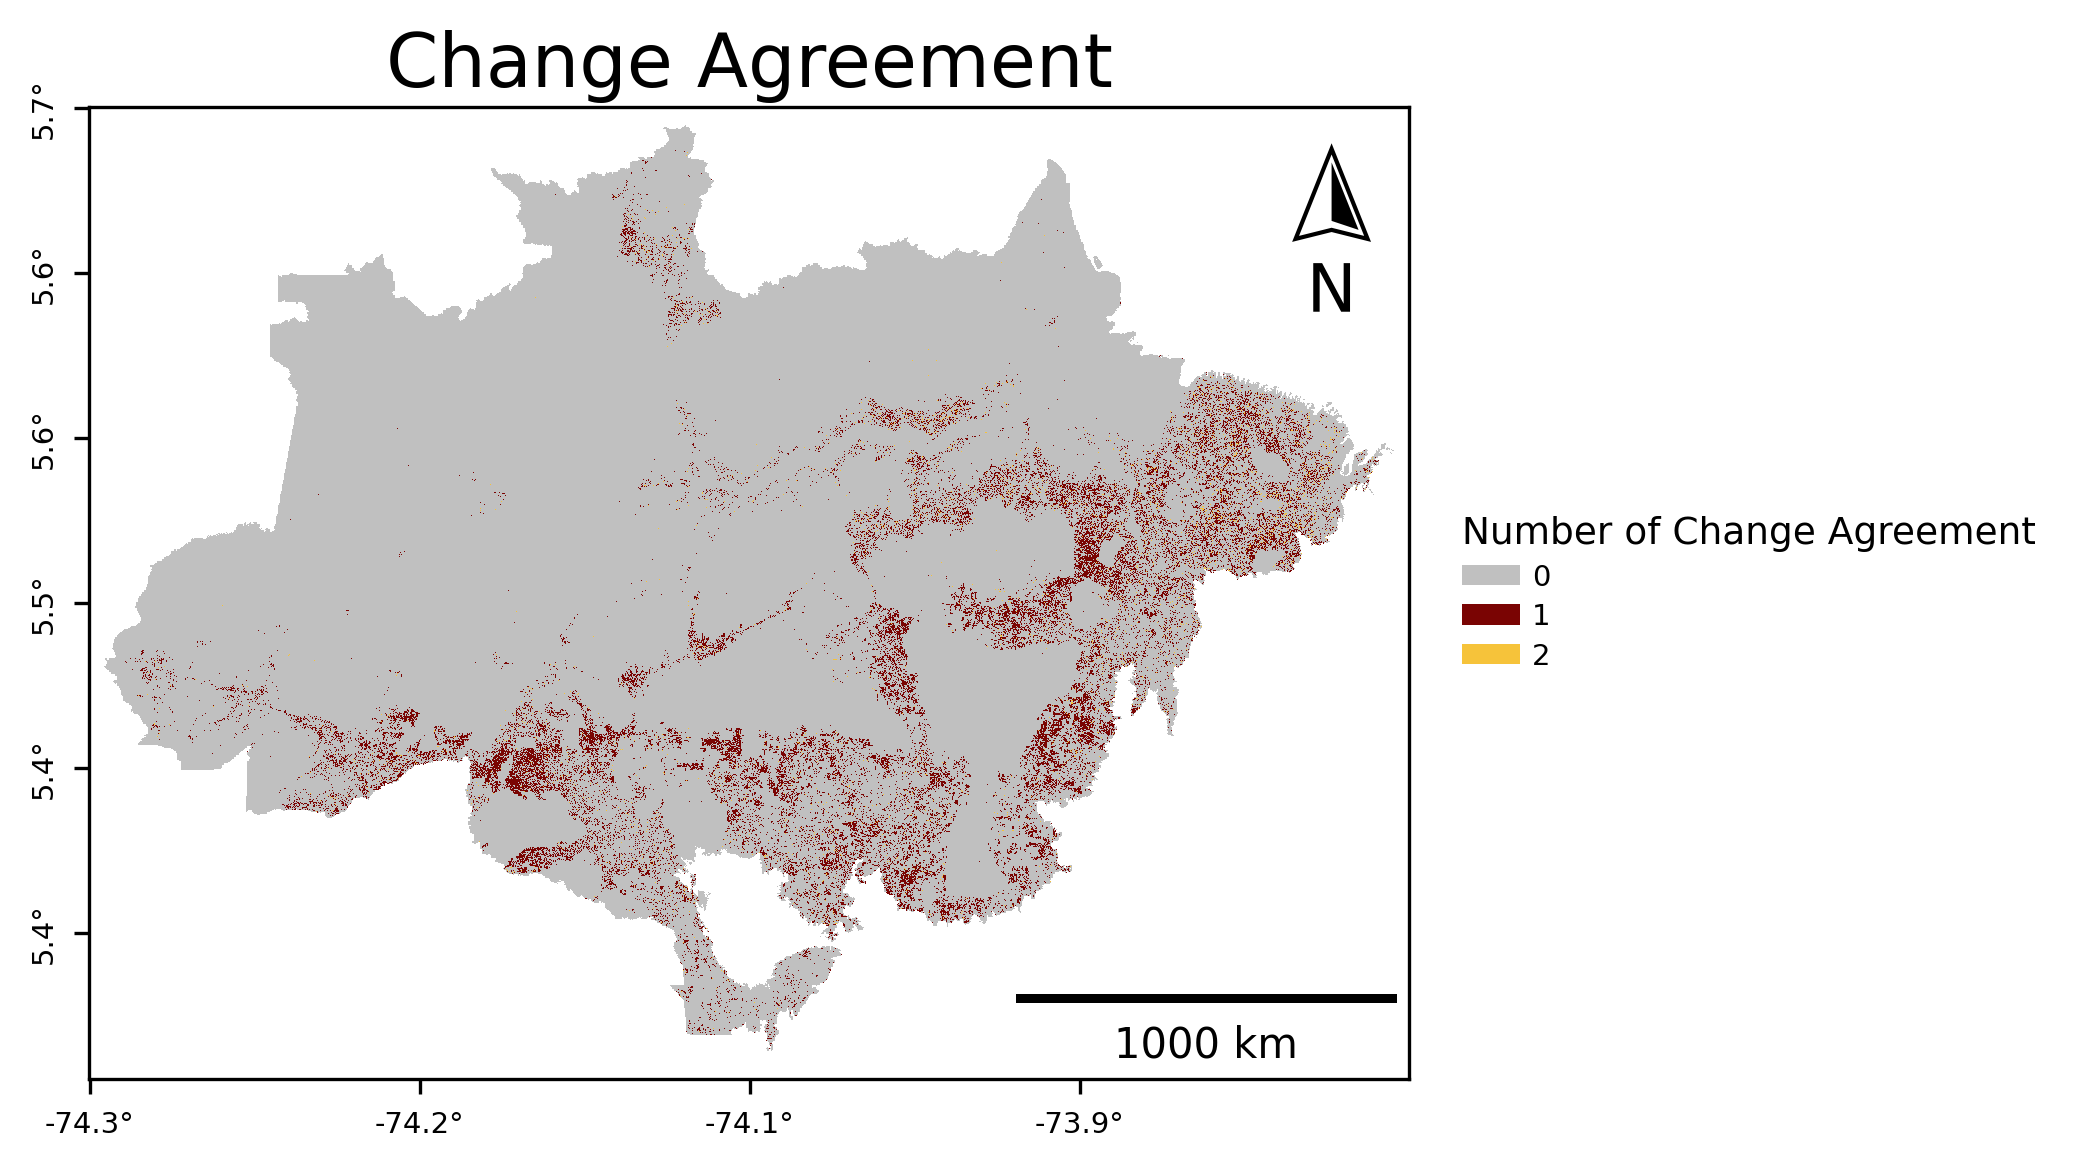

Map successfully saved to: /content/drive/MyDrive/Assessments/compare-time-series/imazon_mapbiomas/output/maps/map_change_agreement.png


In [51]:
# @title 6.6 Plot Change Agreement
_plot_equation_map(
    output_dir=output_path,
    nodata_val=no_data_value,
    raster_filename="eq52_change_agreement.tif",
    title="Change Agreement",
    legend_title="Number of Change Agreement",
    output_png_name="map_change_agreement.png",
    colormap_style="turbo_neg_black",
)


Reading Change Difference map for plotting: /content/drive/MyDrive/Assessments/compare-time-series/imazon_mapbiomas/output/rasters/eq53_change_difference.tif
Loading raster with downsampling factor: 0.02


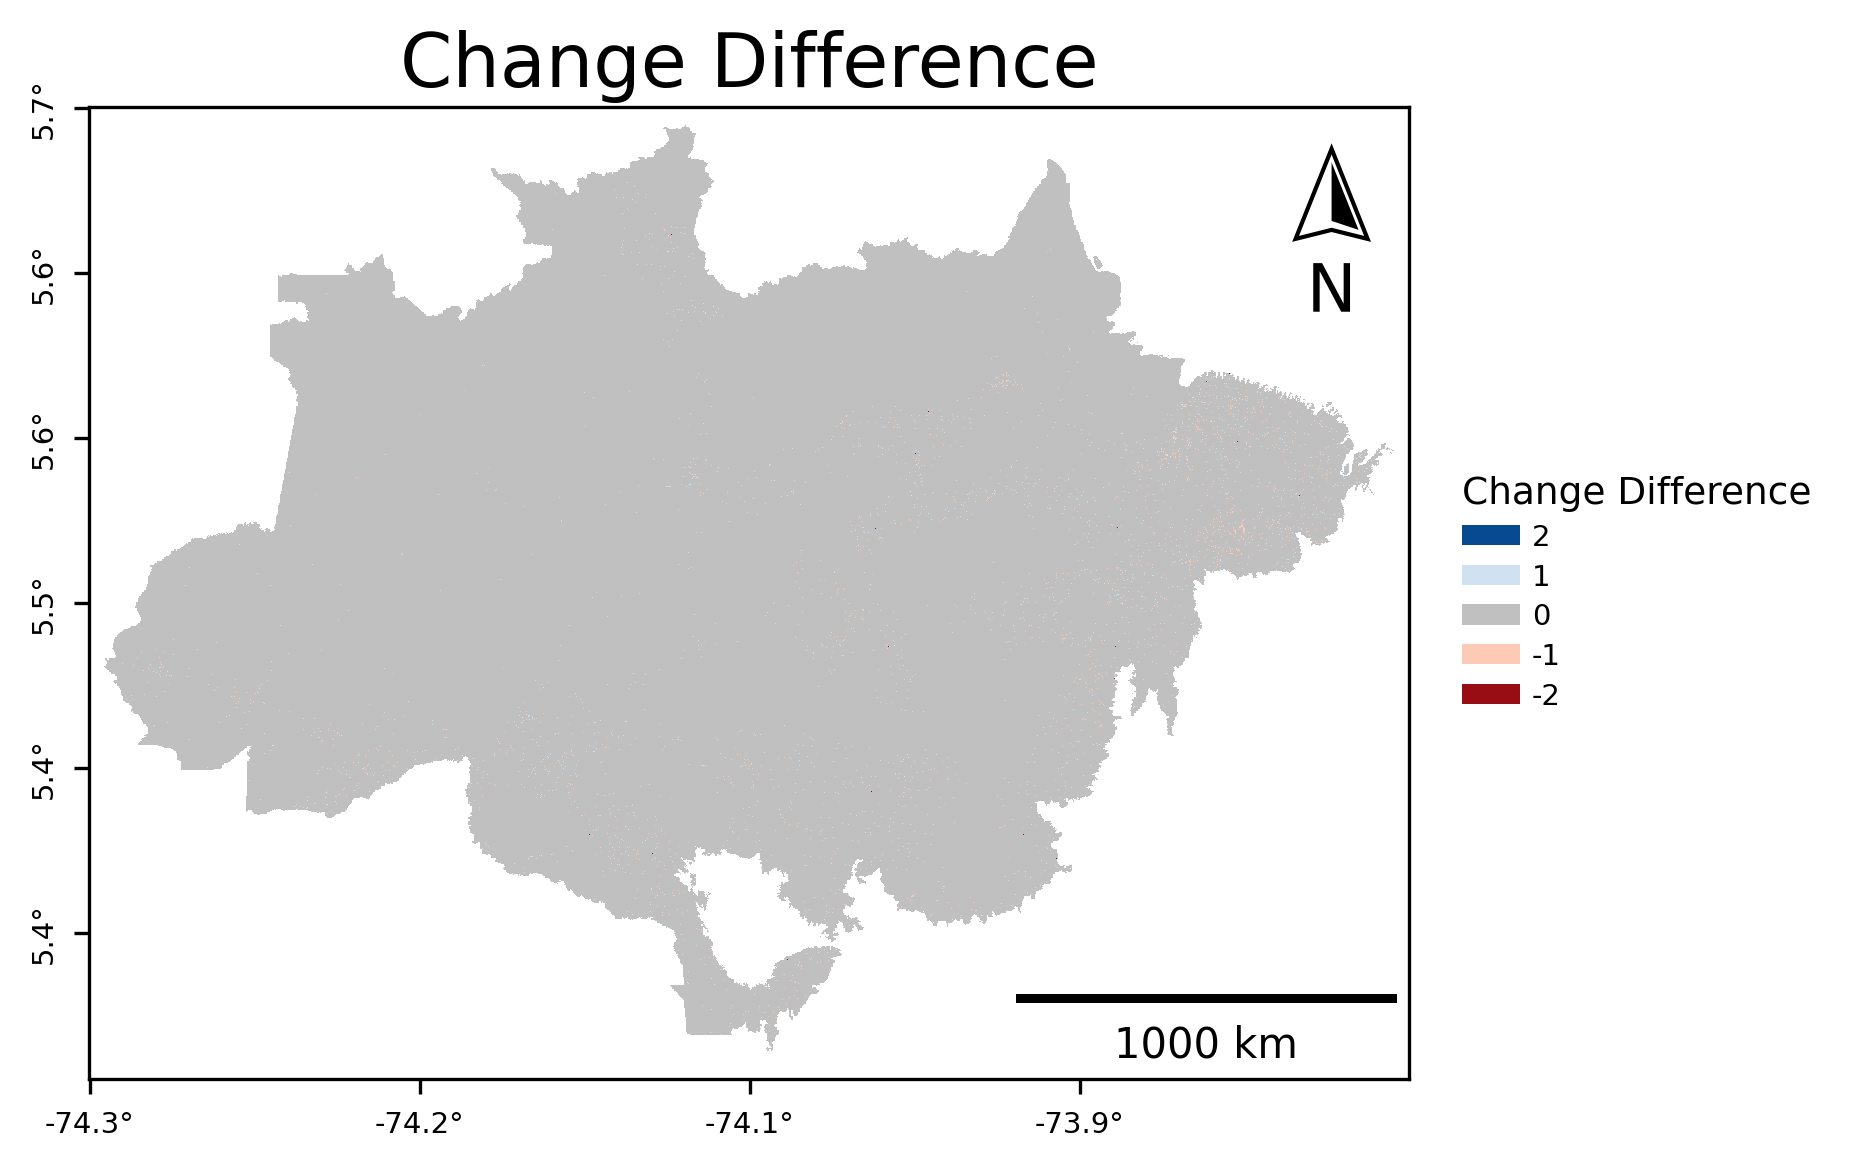

Map successfully saved to: /content/drive/MyDrive/Assessments/compare-time-series/imazon_mapbiomas/output/maps/map_change_difference.png


In [52]:
# @title 6.7 Plot Change Difference
_plot_equation_map(
    output_dir=output_path,
    nodata_val=no_data_value,
    raster_filename="eq53_change_difference.tif",
    title="Change Difference",
    legend_title="Change Difference",
    output_png_name="map_change_difference.png",
    colormap_style="diverging_redblue",
)


Reading Change Absolute Difference map for plotting: /content/drive/MyDrive/Assessments/compare-time-series/imazon_mapbiomas/output/rasters/eq54_change_temporal_allocation.tif
Loading raster with downsampling factor: 0.02


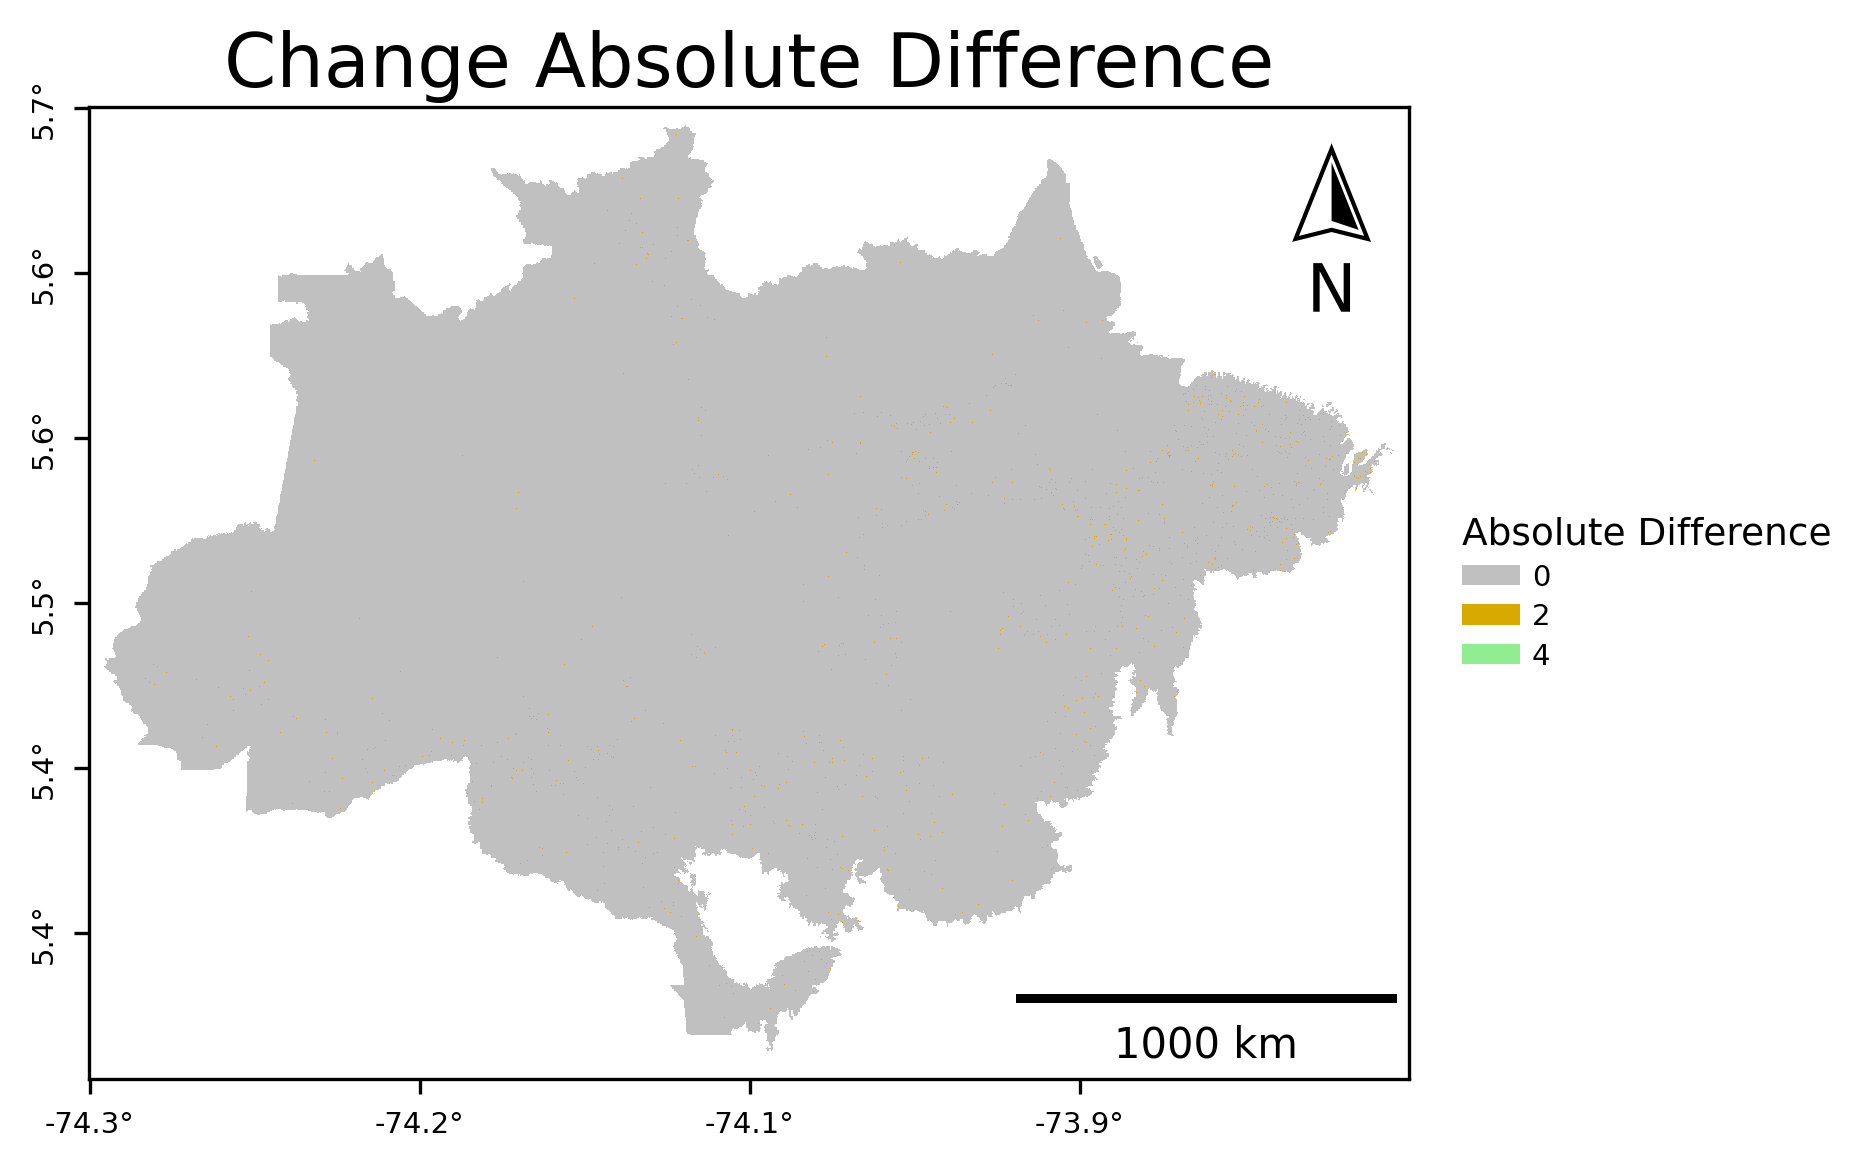

Map successfully saved to: /content/drive/MyDrive/Assessments/compare-time-series/imazon_mapbiomas/output/maps/map_change_absolute_difference.png


In [53]:
# @title 6.8 Plot Change Absolute Difference
_plot_equation_map(
    output_dir=output_path,
    nodata_val=no_data_value,
    raster_filename="eq54_change_temporal_allocation.tif",
    title="Change Absolute Difference",
    legend_title="Absolute Difference",
    output_png_name="map_change_absolute_difference.png",
    colormap_style="redyellowgreen",
)
